# ML2 Semestral Project

**Team members:** 

**Goal.** We predict whether a football match ends with more than 2.5 goals (over/under 2.5). We build two models: a **baseline** model that uses only the data the company has today, and an **extended** model that also uses the richer data offered by the provider. The difference in accuracy between the two models decides how much the company should pay for the richer data.

**Structure of the notebook.**
1. Setup
2. Data loading
3. Data exploration and cleaning: missing values, duplicates, outliers, value validation
4. Feature engineering: target, baseline features, extended features, odds features, checks of the features
5. Train / test split
6. Models
7. Optimal profit increase
8. Correctness checks
9. Conclusion

## 1. Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 2. Data loading

In [2]:
DATA_DIR = Path("data")


def load_data(data_dir=DATA_DIR):
    """Load all data/<country>/<league>/<season>.csv files into one DataFrame."""
    frames = {}
    for path in sorted(Path(data_dir).glob("*/*/*.csv")):
        df = pd.read_csv(path)
        # a few files have trailing commas in the header -> empty "Unnamed" columns
        df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
        # key = (country, league, season), e.g. season "1920" = 2019/20
        frames[path.parts[-3], int(path.parts[-2]), path.stem] = df

    # .copy() consolidates the result (read_csv returns one block per column)
    data = pd.concat(frames, names=["country", "league", "season"]).copy()
    data = data.reset_index(["country", "league", "season"]).reset_index(drop=True)
    data["Date"] = pd.to_datetime(data["Date"], dayfirst=True)
    return data


data = load_data()
data.shape

(42593, 135)

The data is stored as `data/<country>/<league>/<season>.csv`, one file per league and season (126 files). We load all files into one DataFrame with 42,593 matches and 135 columns. Three columns are taken from the file path:
* `country` - the price of the data is calculated per country, so later we need the accuracy per country
* `league` - the tier inside the country (the lower the number, the higher the league)
* `season` - for example `"1920"` is the season 2019/20; we need it for the train/validation/test split

The files do not all have the same columns, because the bookmakers differ between seasons. A column that does not exist in a file is filled with missing values. The meaning of the original columns is described in `notes.txt`.

### 2.1 Data types
Every column except the text columns (teams, division, results, ...) should be numeric. If such a column is stored as text, it contains at least one value that is not a number. We convert these columns to numbers; a value that cannot be converted becomes a missing value.

In [3]:
text_cols = ["country", "season", "Div", "Date", "Time", "HomeTeam", "AwayTeam", "FTR", "HTR", "Referee"]
wrong_type_cols = [col for col in data.columns
                   if col not in text_cols and not pd.api.types.is_numeric_dtype(data[col])]

for col in wrong_type_cols:
    numeric = pd.to_numeric(data[col], errors="coerce")
    not_a_number = data.loc[numeric.isna() & data[col].notna(), col]
    print(f"{col}: {data[col].dtype} -> {numeric.dtype}, values replaced with missing: {not_a_number.tolist()}")
    data[col] = numeric

print()
print(data.dtypes.astype(str).value_counts().to_string())

B365CH: object -> float64, values replaced with missing: ['#']
BWCA: object -> float64, values replaced with missing: ['-']
1XBH: object -> float64, values replaced with missing: ['1xBet']

float64           122
str                 9
int64               3
datetime64[us]      1


Three odds columns were stored as text because of one wrong value each (`#`, `-` and `1xBet`). These three values are now missing and the columns are numeric.

## 3. Data exploration

### 3.1 Missing values

We count the missing values of every column and show them per season in a heatmap. Each cell is the percent of matches of that season in which the column is missing. Only columns with at least one missing value are shown. An empty cell means that nothing is missing; 0.0 means a few missing values that round to zero.

In [4]:
missing = data.isna().sum()
missing = pd.DataFrame({"missing": missing, "percent": (missing / len(data) * 100).round(2)})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)

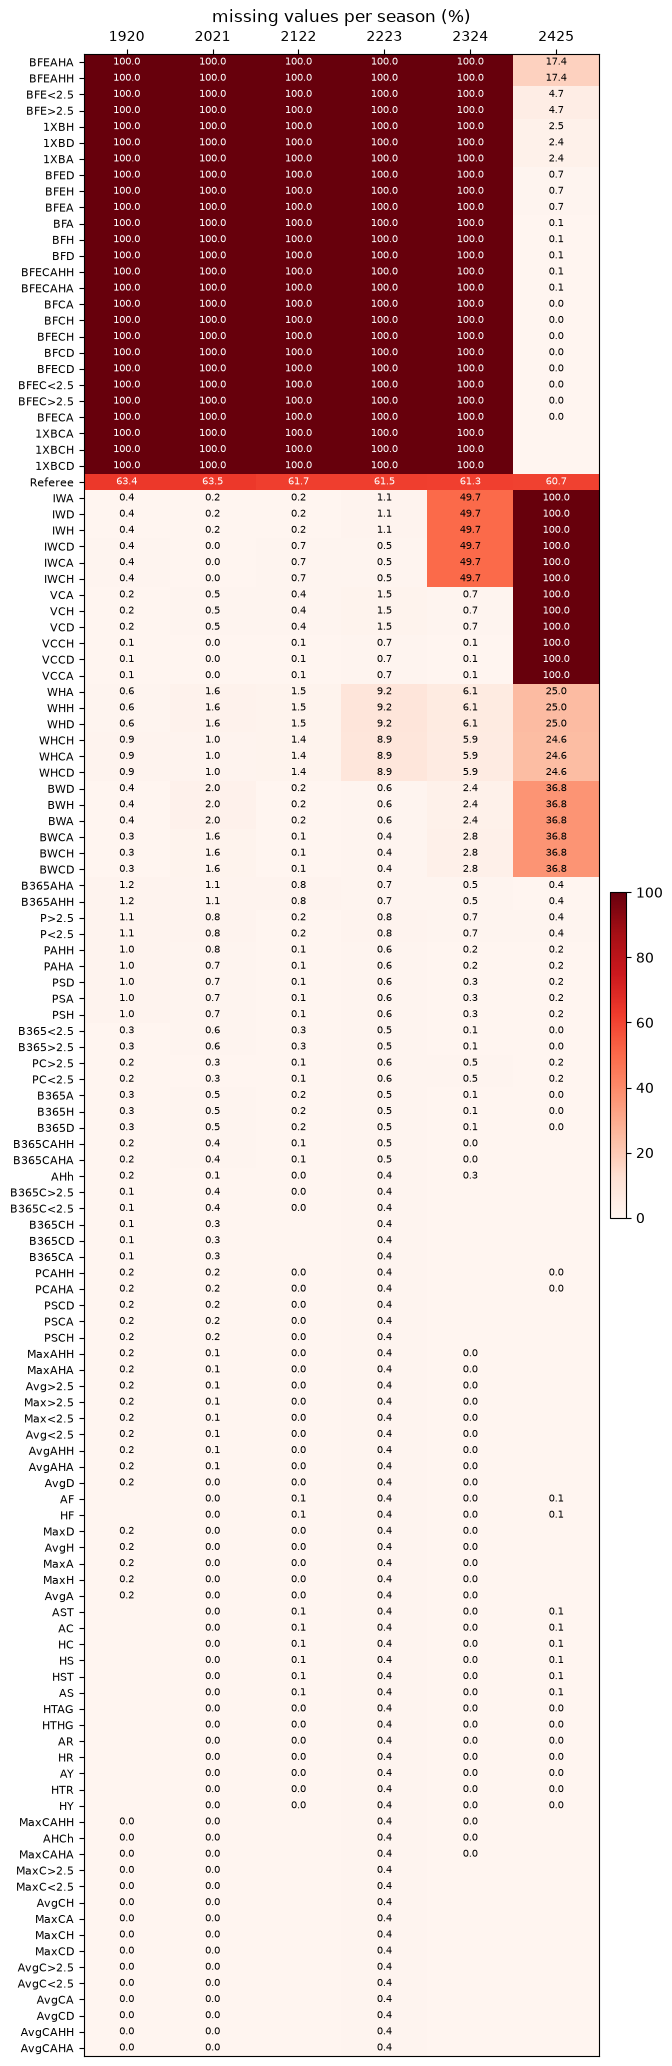

In [5]:
missing_by_season = data.isna().groupby(data["season"]).mean().T * 100
missing_by_season = missing_by_season.loc[missing.index]

fig, ax = plt.subplots(figsize=(7, 26))
im = ax.imshow(missing_by_season, aspect="auto", cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(missing_by_season.shape[1]), missing_by_season.columns)
ax.set_yticks(range(missing_by_season.shape[0]), missing_by_season.index, fontsize=8)
ax.xaxis.tick_top()
ax.set_title("missing values per season (%)")
for y, row in enumerate(missing_by_season.values):
    for x, value in enumerate(row):
        if value > 0:
            ax.text(x, y, f"{value:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if value > 50 else "black")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
plt.show()

What we see in the heatmap and need to analyse further:
* Betfair (`BF`), Betfair Exchange (`BFE`) and 1xBet (`1XB`) odds exist only in 2024/25. Even in that season about 17% of the Betfair Exchange Asian handicap odds are missing, we need to look into that.
* The referee is missing in about 60% of the matches in every season. Maybe it is not available for some leagues.
* Interwetten (`IW`) is half missing in 2023/24 and fully missing in 2024/25. What happened in 2023/24?
* VC Bet (`VC`) is fully missing in 2024/25.
* William Hill (`WH`) is about 25% missing in 2024/25. What happened?
* Bet&Win (`BW`) is about 37% missing in 2024/25. What happened?
* Several bookmakers exist only for a part of the six seasons, so we have to decide whether to keep them.

All other columns (match statistics, Bet365, Pinnacle, market average and maximum) are missing in less than 1.5% of the matches of any season.

In [6]:
league_name = data["country"] + " " + data["league"].astype(str)
month = data["Date"].dt.to_period("M").astype(str)


def missing_pct(cols, by, rows=None):
    """Percent of missing values in `cols`, grouped by `by`, optionally only for `rows`."""
    rows = slice(None) if rows is None else rows
    return data.loc[rows, cols].isna().groupby(by[rows]).mean() * 100


def plot_missing(table, title, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(table, aspect="auto", cmap="Reds", vmin=0, vmax=100)
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=90)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_title(title)
    for y, row in enumerate(table.values):
        for x, value in enumerate(row):
            if value > 0:
                ax.text(x, y, f"{value:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if value > 50 else "black")
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    plt.show()

Two helper functions for the next cells: `missing_pct` gives the percent of missing values in the chosen columns, grouped for example by league or by month (optionally only for some rows). `plot_missing` draws the result as a heatmap.

#### Betfair Exchange in 2024/25

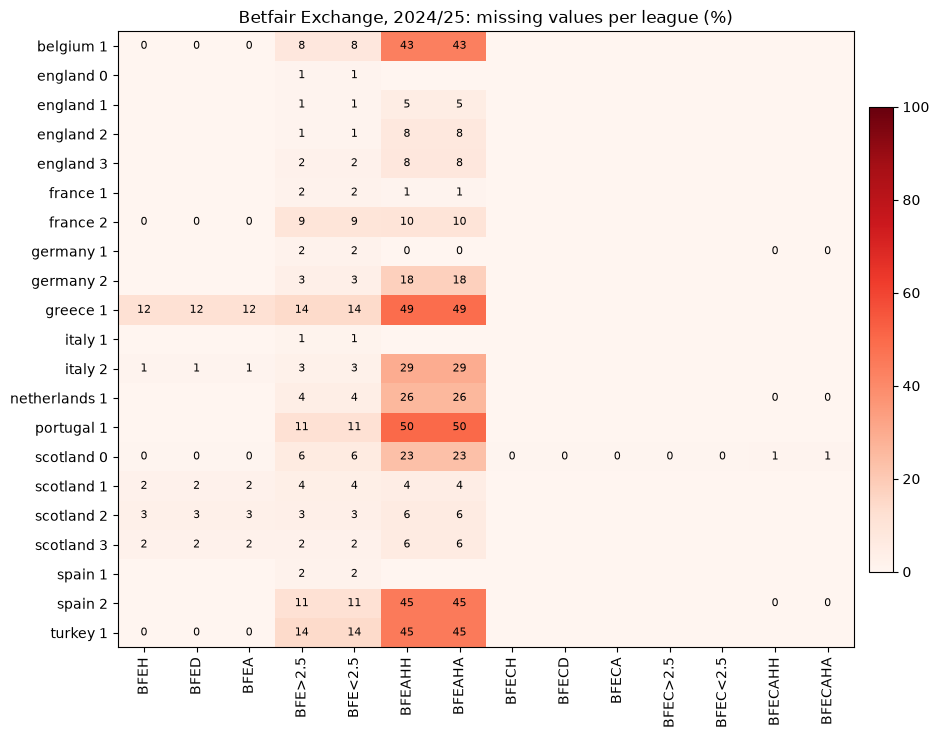

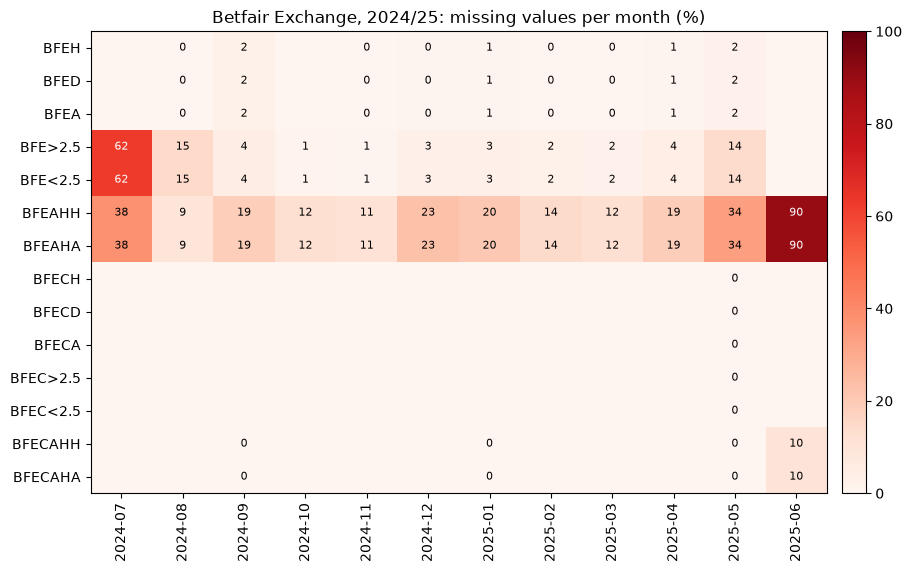

In [7]:
bfe_cols = [col for col in data.columns if col.startswith("BFE")]
last_season = data["season"] == "2425"

plot_missing(missing_pct(bfe_cols, league_name, last_season),
             "Betfair Exchange, 2024/25: missing values per league (%)", figsize=(10, 8))
plot_missing(missing_pct(bfe_cols, month, last_season).T,
             "Betfair Exchange, 2024/25: missing values per month (%)", figsize=(10, 6))

Betfair Exchange analysis
* Every league has data, so no league was left out. The missing values are almost only the Asian handicap odds, mostly in smaller leagues (40 to 50% in Portugal, Greece, Spain 2, Turkey and Belgium, close to 0% in the five biggest leagues).
* The missing values are spread over the whole season, so the bookmaker did not stop at some point. July 2024 and June 2025 only look extreme because they contain very few matches (8 and 10). The 10 matches of June 2025 are 8 matches of the Spanish second division and 2 matches from Turkey.

#### Referee

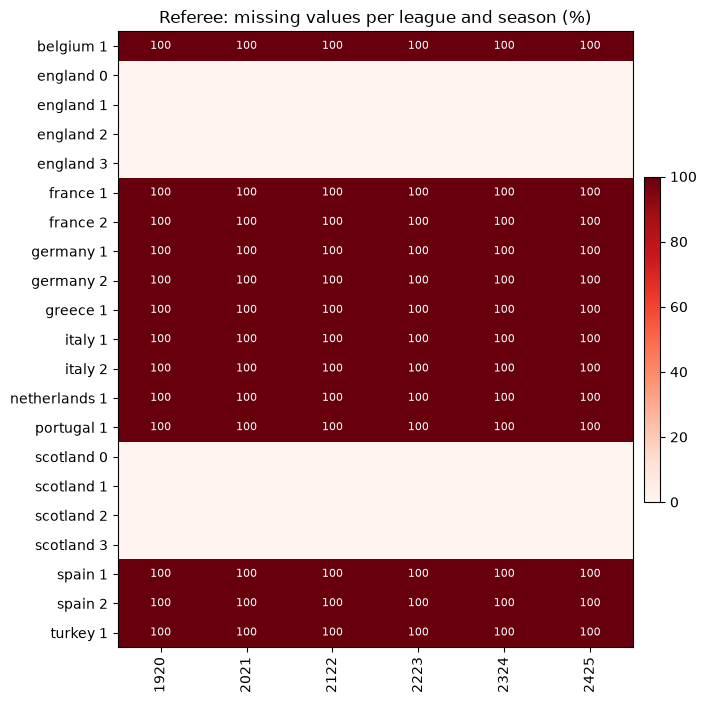

In [8]:
referee = data["Referee"].isna().groupby([league_name, data["season"]]).mean().unstack() * 100

plot_missing(referee, "Referee: missing values per league and season (%)", figsize=(7, 8))

Referee analysis
* The missing values depend only on the league.
* The referee is known for all English and Scottish leagues in every season and missing for all other leagues in every season.

#### Interwetten, VC Bet, William Hill, Bet&Win

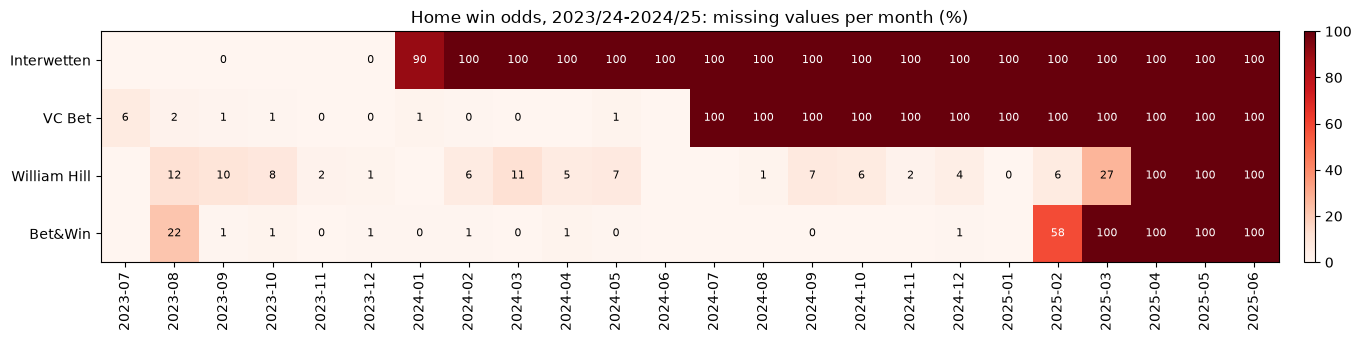

In [9]:
bookmakers = {"IWH": "Interwetten", "VCH": "VC Bet", "WHH": "William Hill", "BWH": "Bet&Win"}
last_two_seasons = data["season"].isin(["2324", "2425"])

timeline = missing_pct(list(bookmakers), month, last_two_seasons).rename(columns=bookmakers)
plot_missing(timeline.T, "Home win odds, 2023/24-2024/25: missing values per month (%)", figsize=(16, 3))

The plot shows the home win odds of the four bookmakers per month in the last two seasons. All four simply stop at some point:
* Interwetten - clean stop in the middle of the season, no odds after 4 January 2024
* VC Bet - complete until the end of 2023/24 (last odds on 2 June 2024), nothing in 2024/25
* William Hill - stops at the end of March 2025
* Bet&Win - stops in the middle of February 2025

The table below shows the last day with odds for every league. Each bookmaker stops in all leagues within a few weeks, so the odds are not missing for some leagues only: the provider stopped collecting them.

In [10]:
last_odds = pd.DataFrame({
    name: data[data[col].notna()].groupby(league_name[data[col].notna()])["Date"].max().dt.date
    for col, name in bookmakers.items()
})
last_odds.loc["all leagues"] = last_odds.max()
last_odds.loc["last match in data"] = data["Date"].max().date()

display(last_odds)

,Interwetten,VC Bet,William Hill,Bet&Win
belgium 1,2023-12-27,2024-06-02,2025-03-16,2025-02-09
england 0,2024-01-02,2024-05-19,2025-03-16,2025-02-03
england 1,2024-01-01,2024-05-04,2025-03-16,2025-02-09
england 2,2024-01-01,2024-04-27,2025-03-27,2025-02-08
england 3,2024-01-01,2024-04-27,2025-03-25,2025-02-08
france 1,2023-12-20,2024-05-19,2025-03-16,2025-02-09
france 2,2023-12-19,2024-05-17,2025-03-15,2025-02-10
germany 1,2023-12-20,2024-05-18,2025-03-16,2025-02-09
germany 2,2023-12-17,2024-05-19,2025-03-16,2025-02-09
greece 1,2024-01-04,2024-05-15,2025-03-09,2025-02-10


#### Correlation of bookmaker odds

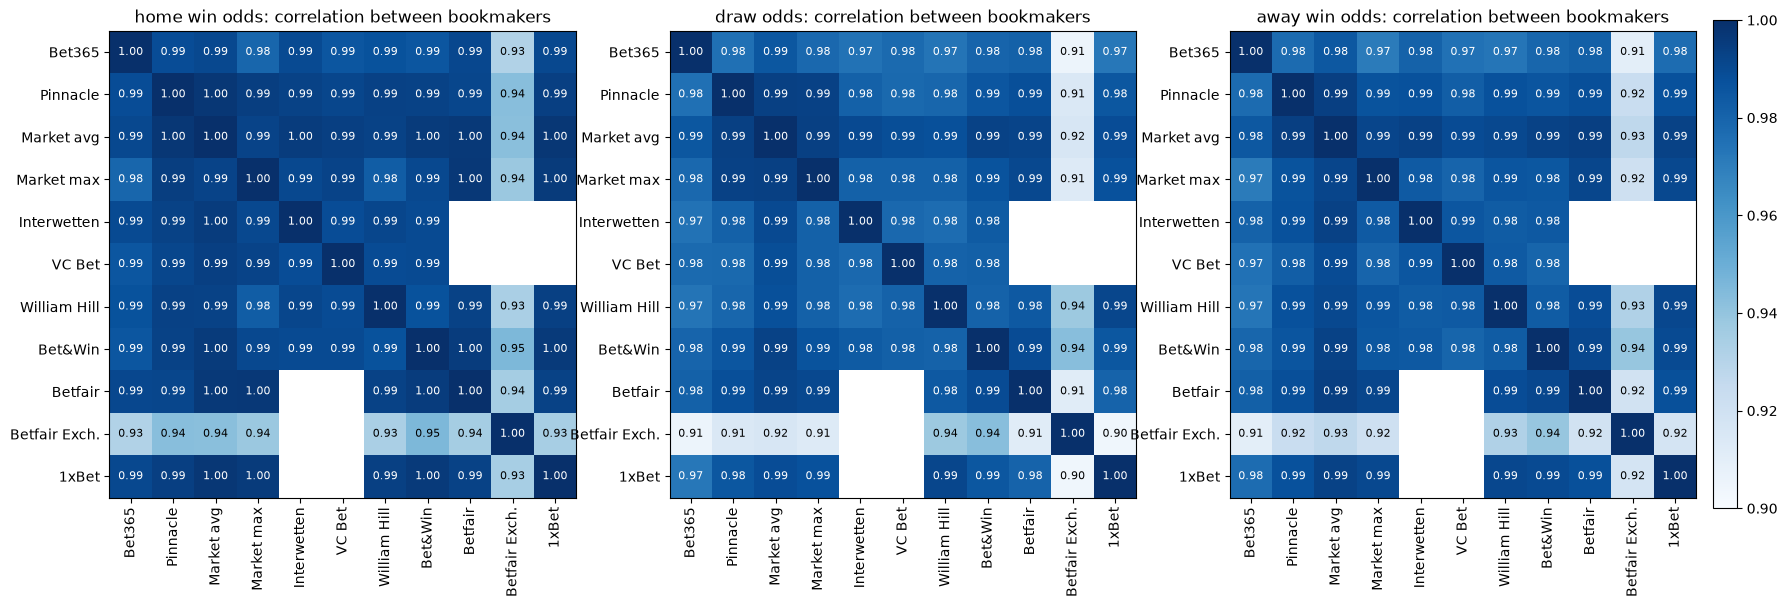

In [11]:
odds_sources = {"B365": "Bet365", "PS": "Pinnacle", "Avg": "Market avg", "Max": "Market max",
                "IW": "Interwetten", "VC": "VC Bet", "WH": "William Hill", "BW": "Bet&Win",
                "BF": "Betfair", "BFE": "Betfair Exch.", "1XB": "1xBet"}
outcomes = {"H": "home win", "D": "draw", "A": "away win"}

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, (suffix, outcome) in zip(axes, outcomes.items()):
    odds = data[[prefix + suffix for prefix in odds_sources]]
    corr = odds.set_axis(list(odds_sources.values()), axis=1).corr()
    im = ax.imshow(corr, cmap="Blues", vmin=0.9, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.index)
    ax.set_title(f"{outcome} odds: correlation between bookmakers")
    for y, row in enumerate(corr.values):
        for x, value in enumerate(row):
            if pd.notna(value):
                ax.text(x, y, f"{value:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if value > 0.97 else "black")
fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01)
plt.show()

The plot shows how strongly the opening odds of the different sources are correlated, separately for home win, draw and away win. An empty cell is a pair of sources that never appears in the same season.
* All bookmakers are very similar to each other and to the market average: the correlations are 0.97 to 1.00. Only Betfair Exchange is a bit lower (0.90 to 0.95).
* So if we drop a bookmaker, almost all of its information is still present in the sources we keep.

#### Dropped features because of missing values

We drop 51 columns:
* Betfair, Betfair Exchange and 1xBet (26 columns) - they have data only in 2024/25. A model trained on the earlier seasons cannot learn anything from them.
* Interwetten, VC Bet, William Hill and Bet&Win (24 columns) - they stop during 2023/24 or 2024/25. These are the seasons we will test on, and the odds will not be delivered in the future either.
* Both groups carry almost the same information as the sources we keep (see the correlation plot), so we lose very little.
* Referee (1 column) - no values outside England and Scotland, and 245 different names that would be hard to encode.

We keep 2 of the 9 bookmakers, Bet365 and Pinnacle, which have data in all six seasons, and the market average and market maximum (`Avg`, `Max`), which summarise many bookmakers.

In [12]:
dropped_prefixes = ("BF", "1XB", "IW", "VC", "WH", "BW")  # "BF" also covers Betfair Exchange (BFE)
dropped_cols = [col for col in data.columns if col.startswith(dropped_prefixes)] + ["Referee"]

data = data.drop(columns=dropped_cols)
print(f"dropped {len(dropped_cols)} columns, {data.shape[1]} remain")
print(dropped_cols)

dropped 51 columns, 84 remain
['BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'WHH', 'WHD', 'WHA', 'VCH', 'VCD', 'VCA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'BFH', 'BFD', 'BFA', '1XBH', '1XBD', '1XBA', 'BFEH', 'BFED', 'BFEA', 'BFE>2.5', 'BFE<2.5', 'BFEAHH', 'BFEAHA', 'BFCH', 'BFCD', 'BFCA', '1XBCH', '1XBCD', '1XBCA', 'BFECH', 'BFECD', 'BFECA', 'BFEC>2.5', 'BFEC<2.5', 'BFECAHH', 'BFECAHA', 'Referee']


After dropping 51 columns, 84 columns remain. More columns are removed later: the market maximum (3.6), the closing odds (4.4) and everything that is only known after the match (end of section 4).

### 3.2 Duplicates

We look for rows that are completely identical and for matches that appear twice (same date, home team and away team).

In [13]:
match_key = ["Date", "HomeTeam", "AwayTeam"]

print("duplicated rows:   ", data.duplicated().sum())
print("duplicated matches:", data.duplicated(match_key).sum())

duplicated rows:    0
duplicated matches: 0


No duplicates were found.

### 3.3 Unique values

The number of different values and the data type of every column. Columns with very few values are categories or small counts (results, cards, goals).

In [14]:
unique = pd.DataFrame({"unique": data.nunique(), "dtype": data.dtypes.astype(str)}).sort_values("unique")

with pd.option_context("display.max_rows", None):
    display(unique)

,unique,dtype
HTR,3,str
FTR,3,str
league,4,int64
HR,4,float64
AR,5,float64
season,6,str
HTHG,8,float64
HTAG,8,float64
FTHG,10,int64
AY,10,float64


### 3.4 Distributions

The first plot shows the distribution of the 16 count columns (goals, shots, fouls, corners, cards). The y-axis is logarithmic, so that a single unusual match is still visible as a small bar far on the right. The second plot shows the number of matches per value of the categorical columns.

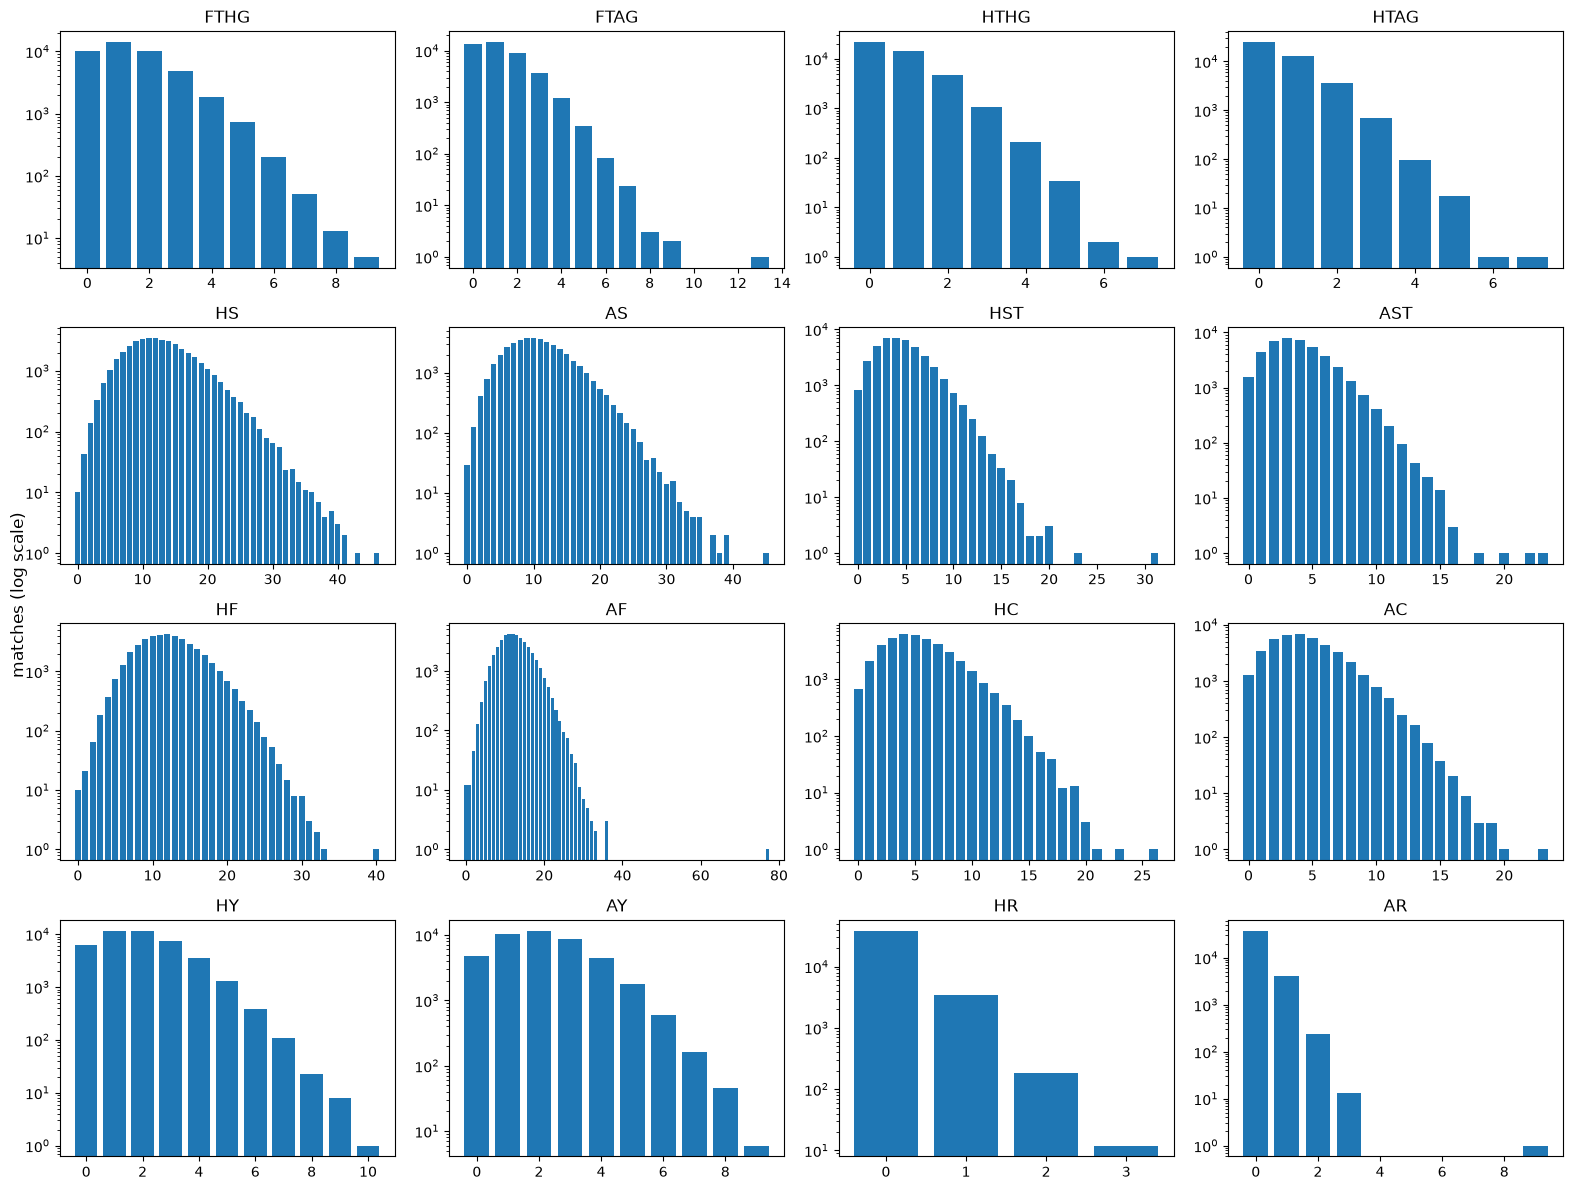

In [15]:
count_cols = ["FTHG", "FTAG", "HTHG", "HTAG", "HS", "AS", "HST", "AST",
              "HF", "AF", "HC", "AC", "HY", "AY", "HR", "AR"]

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flat, count_cols):
    counts = data[col].value_counts().sort_index()
    ax.bar(counts.index, counts.values)
    ax.set_yscale("log")  # log scale so single outlying matches stay visible
    ax.set_title(col)
fig.supylabel("matches (log scale)")
fig.tight_layout()
plt.show()

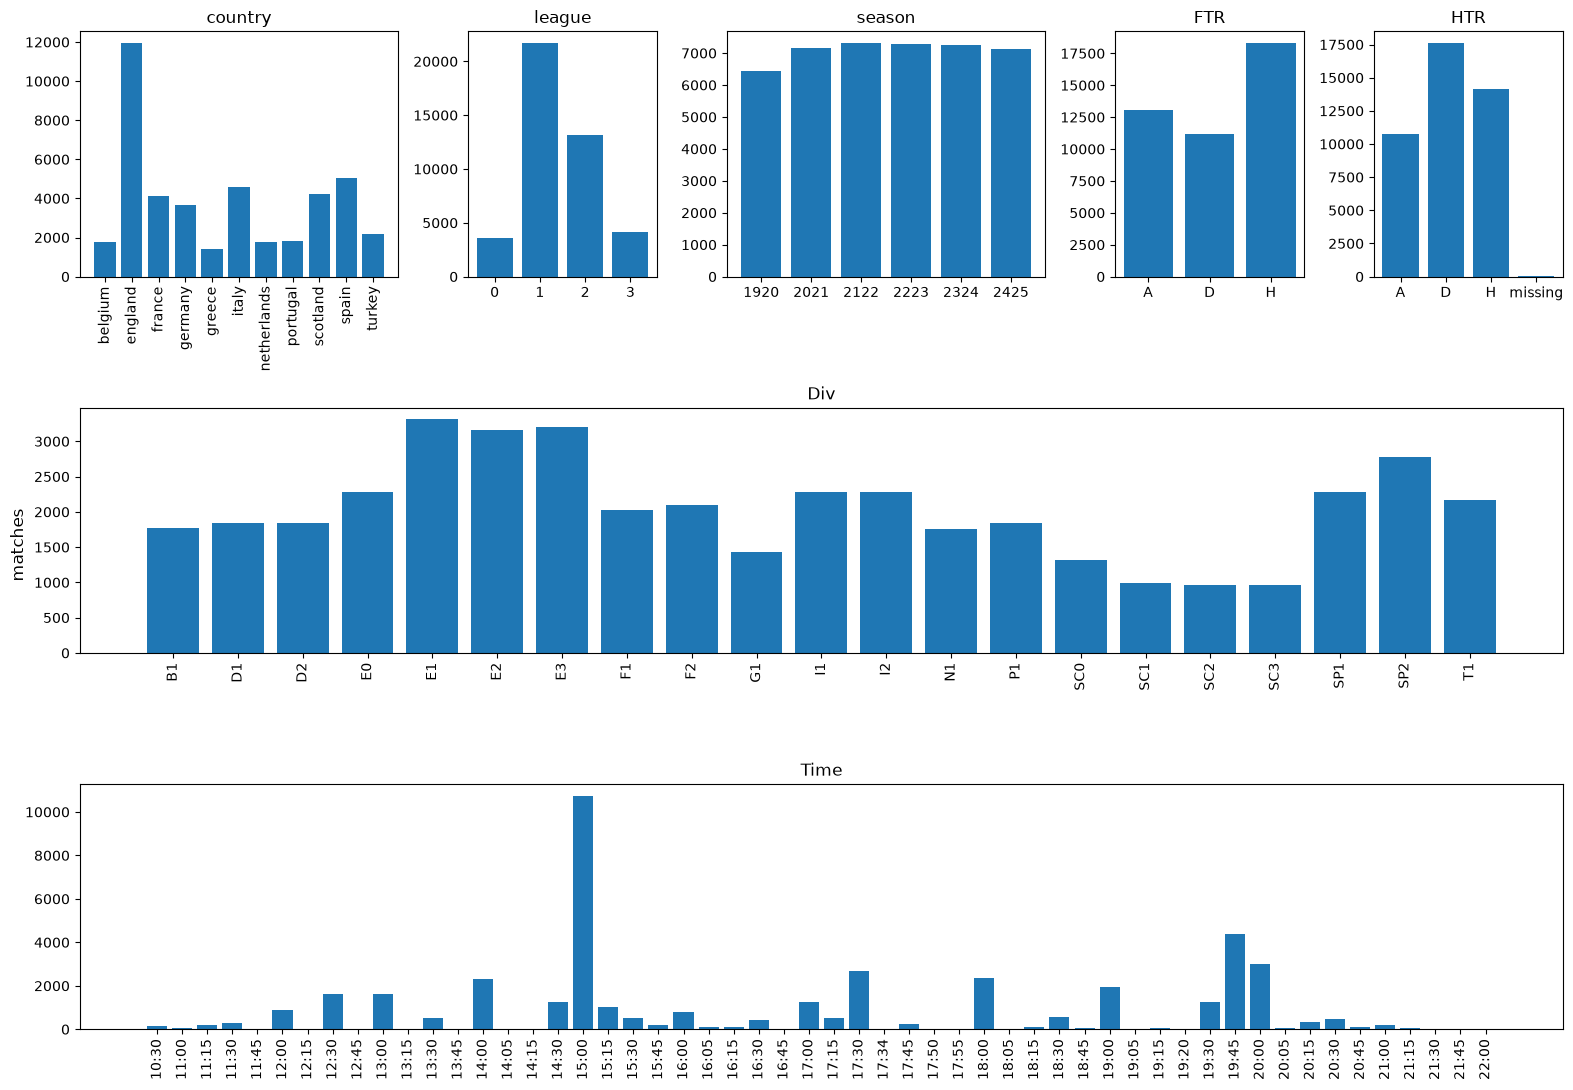

In [16]:
layout = [["country"] * 3 + ["league"] * 2 + ["season"] * 3 + ["FTR"] * 2 + ["HTR"] * 2,
          ["Div"] * 12,
          ["Time"] * 12]

fig, axes = plt.subplot_mosaic(layout, figsize=(16, 11))
for col, ax in axes.items():
    counts = data[col].value_counts(dropna=False).sort_index()
    labels = ["missing" if pd.isna(value) else str(value) for value in counts.index]
    ax.bar(labels, counts.values)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=90 if len(counts) > 6 else 0)
fig.supylabel("matches")
fig.tight_layout()
plt.show()

### 3.5 Summary statistics

The table shows the count, mean, minimum, maximum and quartiles of every numeric column. We use it to find values that cannot be true, i.e. outliers that are input errors and not real extreme values.

In [17]:
with pd.option_context("display.max_rows", None, "display.float_format", "{:.2f}".format):
    display(data.describe(include="number").T)

,count,mean,std,min,25%,50%,75%,max
league,42593.00,1.42,0.78,0.00,1.00,1.00,2.00,3.00
FTHG,42593.00,1.47,1.26,0.00,1.00,1.00,2.00,9.00
FTAG,42593.00,1.20,1.14,0.00,0.00,1.00,2.00,13.00
HTHG,42552.00,0.66,0.82,0.00,0.00,0.00,1.00,7.00
HTAG,42552.00,0.53,0.74,0.00,0.00,0.00,1.00,7.00
HS,42549.00,12.92,5.18,0.00,9.00,12.00,16.00,46.00
AS,42549.00,10.86,4.67,0.00,8.00,10.00,14.00,45.00
HST,42549.00,4.58,2.50,0.00,3.00,4.00,6.00,31.00
AST,42549.00,3.84,2.28,0.00,2.00,4.00,5.00,23.00
HF,42547.00,12.28,4.10,0.00,9.00,12.00,15.00,40.00


Values that look suspicious (chosen by football logic, each one is checked below):
* 13 away goals (`FTAG`)
* 77 away fouls (`AF`)
* 9 away red cards (`AR`)
* home win and away win odds of 76.0 (`MaxH`, `MaxA`)
* closing home win odds of 76.0 (`MaxCH`)
* closing away win odds of 151.0 (`MaxCA`)
* odds of 0, which are not possible (handled in 3.6)

For each of them we print the match together with its other values, so we can judge whether the value is plausible.

In [18]:
match_cols = ["country", "league", "season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]
stat_cols = ["HS", "AS", "HST", "AST", "HF", "AF", "HY", "AY", "HR", "AR"]


def odds_cols(outcome):
    """Bet365, Pinnacle, market average and market maximum odds for one outcome, e.g. "H" or "CA"."""
    return [prefix + outcome for prefix in ("B365", "PS", "Avg", "Max")]

#### 13 away goals (FTAG)

In [19]:
print(data.loc[data["FTAG"] == 13, match_cols + stat_cols].to_string())

           country  league season       Date   HomeTeam AwayTeam  FTHG  FTAG   HS    AS  HST   AST    HF   AF   HY   AY   HR   AR
27802  netherlands       1   2021 2020-10-24  VVV Venlo     Ajax     0    13  3.0  45.0  0.0  23.0  12.0  9.0  1.0  0.0  1.0  0.0


This is a real value: Ajax won 13:0 at VVV Venlo, with 45 shots and 23 shots on target. We keep it.

#### 77 away fouls (AF)

In [20]:
print(data.loc[data["AF"] == 77, match_cols + stat_cols].to_string())

       country  league season       Date HomeTeam      AwayTeam  FTHG  FTAG    HS    AS  HST  AST    HF    AF   HY   AY   HR   AR
11210  england       3   2021 2021-01-02   Bolton  Crawley Town     0     1  24.0  12.0  7.0  5.0  13.0  77.0  1.0  0.0  1.0  0.0


This looks suspicious: 77 fouls and not a single yellow card (the next highest value in the data is 36). We looked the match up on Google: it is a typo and the real value is 7 fouls.

#### 9 away red cards (AR)

In [21]:
print(data.loc[data["AR"] == 9, match_cols + stat_cols].to_string())

      country  league season       Date  HomeTeam AwayTeam  FTHG  FTAG   HS   AS  HST  AST    HF    AF   HY   AY   HR   AR
38231   spain       2   2021 2020-11-13  Zaragoza   Oviedo     1     2  9.0  7.0  4.0  5.0  11.0  17.0  2.0  2.0  1.0  9.0


9 red cards with 17 fouls is not plausible (the next highest value in the data is 3). We looked the match up: the real value is 0.

#### 76.0 home and away win odds (MaxH, MaxA)

In [22]:
print(data.loc[(data["MaxH"] == 76) | (data["MaxA"] == 76), match_cols + odds_cols("H") + odds_cols("A")].to_string())

        country  league season       Date        HomeTeam        AwayTeam  FTHG  FTAG  B365H   PSH   AvgH   MaxH  B365A   PSA   AvgA   MaxA
34143  scotland       2   2324 2024-01-13  Edinburgh City         Falkirk     2     2  21.00   NaN  37.35  76.00   1.06   NaN   1.03   1.06
34192  scotland       2   2324 2024-03-23         Falkirk  Edinburgh City     4     1   1.03  1.02   1.02   1.03  29.00  37.9  38.08  76.00


#### 76.0 closing home win odds (MaxCH)

In [23]:
print(data.loc[data["MaxCH"] == 76, match_cols + odds_cols("H") + odds_cols("CH") + odds_cols("CA")].to_string())

        country  league season       Date        HomeTeam AwayTeam  FTHG  FTAG  B365H  PSH   AvgH  MaxH  B365CH   PSCH  AvgCH  MaxCH  B365CA  PSCA  AvgCA  MaxCA
34143  scotland       2   2324 2024-01-13  Edinburgh City  Falkirk     2     2   21.0  NaN  37.35  76.0    51.0  30.54  43.76   76.0    1.03  1.02   1.02   1.05


All three values of 76.0 belong to two matches of Edinburgh City, an extreme underdog in 2023/24. The market average for the same outcome is about 37 to 44 and Bet365 and Pinnacle are also very high, so 76.0 as the single highest offer on the market is plausible. We keep these values.

#### 151.0 closing away win odds (MaxCA)

In [24]:
print(data.loc[data["MaxCA"] == 151, match_cols + odds_cols("A") + odds_cols("CA") + odds_cols("CH")].to_string())

      country  league season       Date  HomeTeam AwayTeam  FTHG  FTAG  B365A   PSA  AvgA  MaxA  B365CA  PSCA  AvgCA  MaxCA  B365CH  PSCH  AvgCH  MaxCH
40183   spain       2   2425 2024-12-21  Zaragoza   Ferrol     1     0    6.0  6.01   5.7  6.03     7.0  7.37  13.68  151.0     1.5  1.53   1.47   1.57


This is a mistake: Bet365 and Pinnacle offer about 7 for the same outcome, so a maximum of 151 cannot be real. We replace it with a missing value.

#### Replacing invalid values

The two typos get the real values we looked up, and the impossible odds become a missing value.

In [25]:
data.loc[data["AF"] == 77, "AF"] = 7  # typo, actual value looked up
data.loc[data["AR"] == 9, "AR"] = 0  # typo, actual value looked up
data.loc[data["MaxCA"] == 151, "MaxCA"] = np.nan

#### Summary statistics after replacement

We look at the table again: after an outlier is removed, the next highest value becomes visible.

In [26]:
with pd.option_context("display.max_rows", None, "display.float_format", "{:.2f}".format):
    display(data.describe(include="number").T)

,count,mean,std,min,25%,50%,75%,max
league,42593.00,1.42,0.78,0.00,1.00,1.00,2.00,3.00
FTHG,42593.00,1.47,1.26,0.00,1.00,1.00,2.00,9.00
FTAG,42593.00,1.20,1.14,0.00,0.00,1.00,2.00,13.00
HTHG,42552.00,0.66,0.82,0.00,0.00,0.00,1.00,7.00
HTAG,42552.00,0.53,0.74,0.00,0.00,0.00,1.00,7.00
HS,42549.00,12.92,5.18,0.00,9.00,12.00,16.00,46.00
AS,42549.00,10.86,4.67,0.00,8.00,10.00,14.00,45.00
HST,42549.00,4.58,2.50,0.00,3.00,4.00,6.00,31.00
AST,42549.00,3.84,2.28,0.00,2.00,4.00,5.00,23.00
HF,42547.00,12.28,4.10,0.00,9.00,12.00,15.00,40.00


#### 100.0 closing away win odds (MaxCA)

In [27]:
print(data.loc[data["MaxCA"] == 100, match_cols + odds_cols("A") + odds_cols("CA") + odds_cols("CH")].to_string())

      country  league season       Date    HomeTeam AwayTeam  FTHG  FTAG  B365A    PSA   AvgA   MaxA  B365CA   PSCA  AvgCA  MaxCA  B365CH  PSCH  AvgCH  MaxCH
21855  greece       1   2021 2020-12-20  Olympiakos   Larisa     5     1   13.0  19.35  15.19  19.48    19.0  27.67  31.54  100.0    1.08  1.06   1.06   1.09


In [28]:
# the highest closing away win odds next to the other sources
print(data.nlargest(10, "MaxCA")[match_cols[:6] + odds_cols("CA")].to_string())

           country  league season       Date       HomeTeam        AwayTeam  B365CA   PSCA  AvgCA  MaxCA
21855       greece       1   2021 2020-12-20     Olympiakos          Larisa   19.00  27.67  31.54  100.0
35274     scotland       3   2425 2024-12-28          Elgin       Peterhead    2.15   2.32   6.31   81.0
28284  netherlands       1   2122 2022-03-06           Ajax        Waalwijk   41.00  45.32  47.23   80.0
34181     scotland       2   2324 2024-03-09       Hamilton  Edinburgh City   34.00  29.03  32.26   71.0
34192     scotland       2   2324 2024-03-23        Falkirk  Edinburgh City   34.00  47.45  42.46   71.0
31641     scotland       0   2122 2021-12-18        Rangers   Dundee United   41.00  49.66  38.54   67.0
19563      germany       1   2425 2025-02-01  Bayern Munich   Holstein Kiel   29.00  51.00  43.76   65.0
27587  netherlands       1   1920 2019-09-25           Ajax     For Sittard   34.00  38.52  42.94   65.0
42245       turkey       1   2324 2024-05-26     Fenerb

The new maximum is 100.0 (Olympiakos - Larisa). Larisa was a big underdog (market average 31.5, Pinnacle 27.7), so 100 is very high but not impossible, and we keep it.

The second table shows the ten highest closing away win odds next to Bet365 and Pinnacle. The second highest value (81.0, Elgin - Peterhead) is clearly wrong, because both bookmakers offer about 2.2. Checking the maxima one by one would take many rounds, so in the next step we check all of them at once.

#### Market maximum compared to Bet365 and Pinnacle

For every market maximum (`Max...`) we take the odds of Bet365 and Pinnacle for the same outcome and divide the maximum by the higher of the two. Normally the maximum is only a little above the two bookmakers (the ratio is rarely above 1.5).

The table lists every value with a ratio above 3. A ratio above 5 cannot be a real offer, so we treat these values as corrupted. The extreme underdog matches we decided to keep (76.0 and 100.0) have ratios of 3.1 to 3.6.

In [29]:
def reference_odds(suffix):
    """Higher of the Bet365 and Pinnacle odds for one market, e.g. "H", "C>2.5" or "CAHA"."""
    pinnacle = "PS" if suffix in ("H", "D", "A", "CH", "CD", "CA") else "P"
    odds = data[["B365" + suffix, pinnacle + suffix]]
    return odds.where(odds > 1).max(axis=1)


max_cols = [col for col in data.columns if col.startswith("Max")]

checks = []
for col in max_cols:
    reference = reference_odds(col[3:])
    checks.append(data[match_cols[:6]].assign(column=col, maximum=data[col], reference=reference,
                                              ratio=(data[col] / reference).round(2)))
checks = pd.concat(checks)

print(checks[checks["ratio"] > 3].sort_values("ratio", ascending=False).to_string())

        country  league season       Date          HomeTeam        AwayTeam    column  maximum  reference  ratio
22946    greece       1   2425 2025-05-03  Asteras Tripolis       Atromitos     MaxCH     70.0       1.92  36.46
35274  scotland       3   2425 2024-12-28             Elgin       Peterhead     MaxCA     81.0       2.32  34.91
40181     spain       2   2425 2024-12-21            Oviedo         Cordoba     MaxCH     41.0       1.65  24.85
40182     spain       2   2425 2024-12-21          Sp Gijon          Malaga     MaxCH     29.0       1.83  15.85
35276  scotland       3   2425 2024-12-28          Spartans  Edinburgh City     MaxCA     29.0       3.99   7.27
22947    greece       1   2425 2025-05-03         OFI Crete            Aris     MaxCA     12.0       1.86   6.45
35277  scotland       3   2425 2024-12-28         Stranraer           Clyde     MaxCA     15.0       2.52   5.95
35274  scotland       3   2425 2024-12-28             Elgin       Peterhead     MaxCD     21.0  

#### Replacing corrupted closing odds

In [30]:
day_cols = ["country", "league", "Date"]
corrupted_days = checks.loc[checks["ratio"] > 5, day_cols].drop_duplicates()
print(corrupted_days.to_string(index=False))

on_corrupted_day = pd.MultiIndex.from_frame(data[day_cols]).isin(pd.MultiIndex.from_frame(corrupted_days))
closing_market_cols = [col for col in data.columns if col.startswith(("MaxC", "AvgC"))]

data.loc[on_corrupted_day, closing_market_cols] = np.nan
print()
print(f"replaced {len(closing_market_cols)} closing market columns in {on_corrupted_day.sum()} matches")
print(closing_market_cols)

 country  league       Date
  greece       1 2025-05-03
   spain       2 2024-12-21
scotland       3 2024-12-28

replaced 14 closing market columns in 10 matches
['MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA']


All values with a ratio above 5 come from only three match days: Greece on 3 May 2025, the Spanish second division on 21 December 2024 and the Scottish fourth division on 28 December 2024. On these days the closing market odds of the other matches are distorted too, only less strongly, and the market average is affected as well as the maximum.

To be safe we replace the closing market odds (maximum and average, 14 columns) of all 10 matches played on these three days with missing values. The Bet365 and Pinnacle odds of these matches are fine and stay. Other single values may still be wrong; the odds are checked once more in 3.6.

#### Summary statistics after replacement

The inflated closing odds are gone: for example, the highest closing maximum for over 2.5 goals is now 4.6 instead of 11. The second table summarises the text columns.

In [31]:
with pd.option_context("display.max_rows", None, "display.float_format", "{:.2f}".format):
    display(data.describe(include="number").T)

,count,mean,std,min,25%,50%,75%,max
league,42593.00,1.42,0.78,0.00,1.00,1.00,2.00,3.00
FTHG,42593.00,1.47,1.26,0.00,1.00,1.00,2.00,9.00
FTAG,42593.00,1.20,1.14,0.00,0.00,1.00,2.00,13.00
HTHG,42552.00,0.66,0.82,0.00,0.00,0.00,1.00,7.00
HTAG,42552.00,0.53,0.74,0.00,0.00,0.00,1.00,7.00
HS,42549.00,12.92,5.18,0.00,9.00,12.00,16.00,46.00
AS,42549.00,10.86,4.67,0.00,8.00,10.00,14.00,45.00
HST,42549.00,4.58,2.50,0.00,3.00,4.00,6.00,31.00
AST,42549.00,3.84,2.28,0.00,2.00,4.00,5.00,23.00
HF,42547.00,12.28,4.10,0.00,9.00,12.00,15.00,40.00


In [32]:
display(data.describe(exclude="number").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max
country,42593,11,england,11952,NaN,NaN,NaN,NaN,NaN,NaN
season,42593,6,2122,7316,NaN,NaN,NaN,NaN,NaN,NaN
Div,42593,21,E1,3312,NaN,NaN,NaN,NaN,NaN,NaN
Date,42593,NaN,NaN,NaN,2022-07-19 22:58:22.040241,2019-07-26 00:00:00,2021-02-09 00:00:00,2022-08-13 00:00:00,2024-01-12 00:00:00,2025-06-01 00:00:00
Time,42593,54,15:00,10748,NaN,NaN,NaN,NaN,NaN,NaN
HomeTeam,42593,478,Barnsley,138,NaN,NaN,NaN,NaN,NaN,NaN
AwayTeam,42593,478,Middlesbrough,138,NaN,NaN,NaN,NaN,NaN,NaN
FTR,42593,3,H,18310,NaN,NaN,NaN,NaN,NaN,NaN
HTR,42552,3,D,17614,NaN,NaN,NaN,NaN,NaN,NaN


### 3.6 Value validation

The outliers are handled. Now we check rules that every match has to satisfy (for example, odds cannot be below 1). In this section we first only analyse; all changes are made together at the end of the section.

We start with basic rules: no negative values, the date lies inside its season, the kick-off time is a valid time of the day, the home team is not the away team, half-time goals are not above full-time goals, the results (`FTR`, `HTR`) match the goals, and shots on target are not above shots. The first output shows how many matches break each rule, the second one prints these matches.

In [33]:
def expected_result(home_goals, away_goals):
    """Result implied by the goals: H, D or A (missing when the goals are missing)."""
    result = pd.Series(pd.NA, index=home_goals.index, dtype="object")
    result[home_goals > away_goals] = "H"
    result[home_goals == away_goals] = "D"
    result[home_goals < away_goals] = "A"
    return result


def differs(expected, actual):
    """True where the two differ; two missing values count as equal."""
    return ~(expected.eq(actual) | (expected.isna() & actual.isna()))


non_negative = data.select_dtypes("number").drop(columns=["AHh", "AHCh"])  # handicap sizes are negative by design
season_start = pd.to_datetime("20" + data["season"].str[:2] + "-07-01")
season_end = pd.to_datetime("20" + data["season"].str[2:] + "-08-31")
kick_off = pd.to_datetime(data["Time"], format="%H:%M", errors="coerce")

violations = {
    "negative value": (non_negative < 0).any(axis=1),
    "date outside its season (1 July - 31 August)": (data["Date"] < season_start) | (data["Date"] > season_end),
    "kick-off time is not a valid HH:MM time": kick_off.isna(),
    "kick-off before 10:00 or after 23:00": (kick_off.dt.hour < 10) | (kick_off.dt.hour >= 23),
    "home team equals away team": data["HomeTeam"] == data["AwayTeam"],
    "half-time goals above full-time goals": (data["HTHG"] > data["FTHG"]) | (data["HTAG"] > data["FTAG"]),
    "full-time result does not match goals": differs(expected_result(data["FTHG"], data["FTAG"]), data["FTR"]),
    "half-time result does not match goals": differs(expected_result(data["HTHG"], data["HTAG"]), data["HTR"]),
    "shots on target above shots": (data["HST"] > data["HS"]) | (data["AST"] > data["AS"]),
}

print(pd.Series({rule: mask.sum() for rule, mask in violations.items()}, name="matches").to_string())

negative value                                  0
date outside its season (1 July - 31 August)    0
kick-off time is not a valid HH:MM time         0
kick-off before 10:00 or after 23:00            0
home team equals away team                      0
half-time goals above full-time goals           0
full-time result does not match goals           0
half-time result does not match goals           0
shots on target above shots                     6


In [34]:
for rule, mask in violations.items():
    if mask.any():
        print(rule)
        print(data.loc[mask, match_cols + stat_cols].to_string())
        print()

shots on target above shots
        country  league season       Date     HomeTeam        AwayTeam  FTHG  FTAG    HS   AS  HST  AST    HF    AF   HY   AY   HR   AR
2542    england       0   2122 2021-08-15    Newcastle        West Ham     2     4  17.0  8.0  3.0  9.0   4.0   3.0  1.0  0.0  0.0  0.0
6993    england       1   2425 2024-11-10      Burnley         Swansea     1     0   2.0  9.0  7.0  4.0  13.0  12.0  1.0  3.0  0.0  0.0
9358    england       2   2223 2023-04-15   Accrington  Fleetwood Town     2     5  15.0  2.0  3.0  6.0  14.0  15.0  2.0  4.0  1.0  0.0
32842  scotland       1   2122 2022-02-25     Hamilton     Inverness C     1     1   9.0  5.0  4.0  7.0  12.0  18.0  1.0  2.0  0.0  0.0
33266  scotland       1   2425 2024-08-24  Airdrie Utd     Queens Park     0     2  11.0  2.0  2.0  4.0  14.0  12.0  3.0  2.0  0.0  1.0
39996     spain       2   2425 2024-09-07       Huesca          Burgos     0     1  12.0  5.0  1.0  7.0  10.0   9.0  5.0  2.0  1.0  0.0



Only one rule is broken: in 6 matches a team has more shots on target than shots. We looked up the real number of shots on Google and correct them at the end of this section. All other rules hold. The data has no column with the total number of goals, so there is nothing to compare the sum of the goals with.

#### Goals above shots on target

A goal normally comes from a shot on target. A team can score more goals than it has shots on target only through own goals of the opponent, and two or more own goals in one match are very rare. So we list the matches in which a team scored at least 2 goals more than its shots on target.

In [ ]:
goals_above_on_target = ((data["FTHG"] - data["HST"]) >= 2) | ((data["FTAG"] - data["AST"]) >= 2)

print(f"{goals_above_on_target.sum()} matches")
print(data.loc[goals_above_on_target, match_cols + ["HTHG", "HTAG", "HS", "AS", "HST", "AST"]].to_string())

All six results are real, so the goals and the target are correct. We looked up the shots on target of all six matches:
* Panetolikos - Larisa (3:0) stood out most: half-time 0:0 and no shot on target of Panetolikos at all. The match was played and all three goals came in the second half; Panetolikos had 3 shots on target.
* The shots on target of Sandhausen (4 instead of 2), Utrecht (5 instead of 1) and Chaves (3 instead of 0) were recorded too low.
* The values of Luton (1) and Portsmouth (0) are correct as they are.

We correct the four wrong values at the end of this section. Other shots-on-target values may be incomplete as well, but only these six were suspicious enough to stand out, and we cannot check every match by hand.

#### Odds of 1 or below

In [35]:
not_odds = count_cols + ["league", "AHh", "AHCh"]
odds_value_cols = [col for col in data.select_dtypes("number").columns if col not in not_odds]

invalid_odds = data[odds_value_cols].where(data[odds_value_cols] <= 1).stack().dropna()
invalid_odds = invalid_odds.rename_axis(["row", "column"]).rename("value").reset_index("column")
invalid_odds = data[match_cols[:6]].join(invalid_odds, how="inner")

print(f"{len(invalid_odds)} values in {invalid_odds.index.nunique()} matches")
print(invalid_odds.to_string())

22 values in 11 matches
        country  league season       Date        HomeTeam     AwayTeam     column  value
2700    england       0   2122 2021-12-19       Newcastle     Man City  B365C>2.5   0.00
2700    england       0   2122 2021-12-19       Newcastle     Man City  B365C<2.5   0.00
7948    england       2   2021 2020-12-05      Sunderland        Wigan      B365H   0.00
15712    france       1   2425 2025-04-19        Paris SG     Le Havre      P>2.5   0.00
15712    france       1   2425 2025-04-19        Paris SG     Le Havre      P<2.5   0.00
15712    france       1   2425 2025-04-19        Paris SG     Le Havre     PC>2.5   0.00
15712    france       1   2425 2025-04-19        Paris SG     Le Havre     PC<2.5   0.00
18120   germany       1   1920 2020-06-01         FC Koln   RB Leipzig   AvgC>2.5   0.42
19684   germany       1   2425 2025-05-10   Bayern Munich   M'gladbach      P>2.5   0.00
19684   germany       1   2425 2025-05-10   Bayern Munich   M'gladbach      P<2.5   0.

Decimal odds are always above 1 (odds of exactly 1 would pay no winnings). We found 21 odds of 0.00 and one of 0.42, which is not possible. All 22 values will be replaced with missing values.

#### Fouls and corners of 0

In [36]:
fouls_cols = match_cols + ["HF", "AF", "HY", "AY", "HR", "AR", "HC", "AC", "HS", "AS"]
zero_fouls = (data["HF"] == 0) | (data["AF"] == 0)
both_zero_fouls = (data["HF"] == 0) & (data["AF"] == 0)

print("matches per number of fouls (lowest values)")
print(pd.DataFrame({col: data[col].value_counts().sort_index().head(6) for col in ["HF", "AF"]}).T.to_string())
print()
print(f"0 fouls for at least one team: {zero_fouls.sum()} matches, for both teams: {both_zero_fouls.sum()} matches")
print(f"both teams with 0 fouls expected by chance: {(data['HF'] == 0).mean() * (data['AF'] == 0).mean() * len(data):.3f} matches")
print()
print(data.loc[zero_fouls, fouls_cols].sort_values(["country", "Date"]).to_string())

matches per number of fouls (lowest values)
    0.0  1.0  2.0  3.0  4.0  5.0
HF   10   21   64  188  372  745
AF   12   12   45  127  306  676

0 fouls for at least one team: 16 matches, for both teams: 6 matches
both teams with 0 fouls expected by chance: 0.003 matches

           country  league season       Date          HomeTeam          AwayTeam  FTHG  FTAG    HF    AF   HY   AY   HR   AR   HC    AC    HS    AS
1906       england       0   1920 2019-11-30           Chelsea          West Ham     0     1   0.0  16.0  0.0  3.0  0.0  0.0  9.0   3.0  19.0   5.0
14759       france       1   2122 2022-05-21             Lille            Rennes     2     2  12.0   0.0  2.0  2.0  0.0  0.0  7.0   4.0  13.0  13.0
17555       france       2   2425 2024-08-16           Ajaccio             Rodez     1     0   2.0   0.0  2.0  0.0  0.0  0.0  3.0   4.0   8.0   5.0
17559       france       2   2425 2024-08-16          Grenoble             Laval     2     1   1.0   0.0  2.0  0.0  0.0  0.0  4.0   4.0 

The first table shows how many matches have 0, 1, 2, ... fouls of the home and of the away team. A team that commits 0 fouls in a whole match is very unlikely. 16 matches have 0 fouls for at least one team and 6 of them for both teams, while by chance we would expect 0.003 such matches. In several of these matches cards were shown, which makes 0 fouls even less believable. So 0 means "not recorded" here, and all 22 zero values will be replaced with missing values.

In [37]:
both_zero_corners = (data["HC"] == 0) & (data["AC"] == 0)

print("matches per number of corners (lowest values)")
print(pd.DataFrame({col: data[col].value_counts().sort_index().head(4) for col in ["HC", "AC"]}).T.to_string())
print()
print(f"0 corners for both teams: {both_zero_corners.sum()} matches")
print(f"both teams with 0 corners expected by chance: {(data['HC'] == 0).mean() * (data['AC'] == 0).mean() * len(data):.1f} matches")
print()
print(data.loc[both_zero_corners, fouls_cols].to_string())

matches per number of corners (lowest values)
     0.0   1.0   2.0   3.0
HC   680  2097  3974  5468
AC  1255  3432  5575  6719

0 corners for both teams: 5 matches
both teams with 0 corners expected by chance: 20.0 matches

           country  league season       Date     HomeTeam       AwayTeam  FTHG  FTAG    HF    AF   HY   AY   HR   AR   HC   AC    HS    AS
6728       england       1   2324 2024-04-01   Birmingham        Preston     1     0   7.0   9.0  1.0  1.0  0.0  0.0  0.0  0.0  11.0   4.0
27503        italy       2   2425 2025-05-04  Salernitana        Mantova     2     0  20.0  16.0  0.0  2.0  0.0  0.0  0.0  0.0  13.0   7.0
27987  netherlands       1   2021 2021-03-14    VVV Venlo    For Sittard     1     3  13.0  12.0  3.0  1.0  0.0  0.0  0.0  0.0   9.0  10.0
29554     portugal       1   1920 2020-07-05  Gil Vicente        Rio Ave     1     0   0.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0  13.0   5.0
35093     scotland       3   2324 2023-12-30        Clyde  Stenhousemuir     1   

Corners are different. One team often has 0 corners, so both teams with 0 corners should happen about 20 times by chance, and we see it only 5 times. We also looked up the five matches and they really had 0 corners. Nothing is changed.

#### Asian handicap sign

The Asian handicap (`AHh` for the opening odds, `AHCh` for the closing odds) is the number of goals that is added to the result of the home team for the bet. It is negative when the home team is the favourite and positive when it is the underdog. We compare its sign with the home and away win odds.

In [38]:
# the handicap is given for the home team: negative when the home team is the favourite
handicap_cols = {"AHh": ("AvgH", "AvgA", "AvgAHH", "AvgAHA"), "AHCh": ("AvgCH", "AvgCA", "AvgCAHH", "AvgCAHA")}

for handicap, (home, away, handicap_home, handicap_away) in handicap_cols.items():
    home_favourite = data[home] < data[away]
    away_favourite = data[home] > data[away]
    wrong_sign = ((data[handicap] > 0) & home_favourite) | ((data[handicap] < 0) & away_favourite)
    print(f"{handicap}: sign contradicts the favourite in {wrong_sign.sum()} matches")
    print(data.loc[wrong_sign, match_cols[:6] + [home, away, "AHh", "AHCh", handicap_home, handicap_away]].to_string())
    print()

AHh: sign contradicts the favourite in 1 matches
      country  league season       Date HomeTeam     AwayTeam  AvgH   AvgA  AHh  AHCh  AvgAHH  AvgAHA
22374  greece       1   2223 2023-01-15      AEK  Panetolikos  1.14  18.29  2.5  -2.0    1.63    2.23

AHCh: sign contradicts the favourite in 3 matches
           country  league season       Date    HomeTeam   AwayTeam  AvgCH  AvgCA  AHh  AHCh  AvgCAHH  AvgCAHA
26372        italy       2   2122 2022-04-30        Spal  Frosinone   2.95   2.45  0.0 -0.25     2.51     1.52
29029  netherlands       1   2425 2024-09-21    Nijmegen   Heracles   1.64   4.97 -1.0  1.50     1.86     1.87
41079       turkey       1   2021 2021-04-20  Karagumruk     Goztep   2.86   2.54  0.0 -0.25     2.10     1.76



A favourite should not have a positive handicap and an underdog should not have a negative one. The sign contradicts the favourite in 1 opening and 3 closing handicaps.

As a second check we compare every handicap with the typical handicap of matches with similar home and away win odds, and list the matches that differ by 1 goal or more.

In [39]:
# handicap compared to the typical handicap of matches with similar home and away win odds
for handicap, (home, away, handicap_home, handicap_away) in handicap_cols.items():
    odds_bin = pd.cut(np.log(data[away] / data[home]), 40)
    typical = data.groupby(odds_bin, observed=True)[handicap].transform("median")
    deviation = (data[handicap] - typical).abs()
    print(f"{handicap}: deviation from the typical handicap")
    print(deviation.describe(percentiles=[0.5, 0.99, 0.999]).round(2).to_frame().T.to_string(index=False))
    print(data.loc[deviation >= 1, match_cols[:6] + [home, away, handicap, handicap_home, handicap_away]]
          .assign(typical=typical).to_string())
    print()

AHh: deviation from the typical handicap
  count  mean  std  min  50%  99%  99.9%  max
42527.0  0.05 0.11  0.0  0.0 0.25    0.5 4.75
       country  league season       Date       HomeTeam     AwayTeam  AvgH   AvgA  AHh  AvgAHH  AvgAHA  typical
1950   england       0   1920 2019-12-21       Man City    Leicester  1.37   7.72 -2.5    3.38    1.32    -1.25
19433  germany       1   2425 2024-09-28  Bayern Munich   Leverkusen  1.73   4.22 -2.5    4.61    1.19    -0.50
20434  germany       2   2122 2021-11-24       St Pauli   Sandhausen  1.36   7.39 -2.5    3.38    1.32    -1.25
22374   greece       1   2223 2023-01-15            AEK  Panetolikos  1.14  18.29  2.5    1.63    2.23    -2.25
23129    italy       1   1920 2019-12-21          Inter        Genoa  1.35   9.17 -2.5    3.61    1.29    -1.50

AHCh: deviation from the typical handicap
  count  mean  std  min  50%  99%  99.9%  max
42550.0  0.05 0.11  0.0  0.0 0.25    0.5 2.25
           country  league season       Date    HomeTeam    

Most of the listed handicaps of -2.5 are not errors: their handicap odds are very unbalanced (for example 4.61 against 1.19), which shows that a different, harder handicap was offered in that match. The only real errors are the wrong signs. Where the sign does not match the favourite, we flip it.

#### Market maximum below market average

A maximum cannot be lower than the average of the same odds. For every market the table counts how often the market maximum is below the market average, and how often it is below the odds of Bet365 or Pinnacle.

In [40]:
market_suffixes = [col[3:] for col in max_cols]

rows = []
for suffix in market_suffixes:
    maximum, average = data["Max" + suffix].where(data["Max" + suffix] > 1), data["Avg" + suffix]
    bookmakers = reference_odds(suffix)
    rows.append({"market": suffix,
                 "max below avg": (maximum < average).sum(),
                 "max below Bet365/Pinnacle": (maximum < bookmakers).sum(),
                 "by more than 5%": (maximum < bookmakers * 0.95).sum(),
                 "by more than 10%": (maximum < bookmakers * 0.90).sum()})
print(pd.DataFrame(rows).to_string(index=False))

market  max below avg  max below Bet365/Pinnacle  by more than 5%  by more than 10%
     H              0                         49               12                 5
     D              1                         30                4                 1
     A              0                         68               12                 7
  >2.5              0                        132               14                 2
  <2.5              0                         38                1                 1
   AHH              2                         92               15                 8
   AHA              0                         77               10                 4
    CH              0                          8                5                 3
    CD              0                         18                3                 2
    CA              0                         18                5                 2
 C>2.5              0                        112               33           

The maximum is below the average in 6 cases, which is impossible by definition. In these cases the average is often the value that is out of line. The maximum is also below Bet365 or Pinnacle in many matches, usually only by a few percent, so it is not always the real highest value on the market.

Together with the errors found in 3.5, this makes the market maximum the least reliable group of columns. It also carries almost the same information as the market average, which we keep (correlation 0.94 to 0.99). We therefore drop all 14 `Max` columns.

#### Implied probabilities
Now we check whether the odds of one source make sense together. Odds $o$ imply a probability of $1 / o$. For one source, the implied probabilities of all outcomes of a market (home win, draw and away win; over and under 2.5; the two sides of the Asian handicap) must sum to a little more than 1. The part above 1 is the margin of the bookmaker.

* A sum below 1 would mean a guaranteed profit for the bettor, so it cannot be right.
* A very high sum means that at least one of the odds is too low.

The table shows this sum for every source (Bet365, Pinnacle, market average), market and timing (opening, closing): the lowest, typical and highest values, and how many matches are below 1 or above 1.15.

In [41]:
# implied probability = 1 / odds; for one source the outcomes of a market sum to 1 + margin
source_prefixes = {"Bet365": ("B365", "B365"), "Pinnacle": ("PS", "P"), "Market avg": ("Avg", "Avg")}
market_outcomes = {"win/draw/away": ["H", "D", "A"], "over/under 2.5": [">2.5", "<2.5"], "Asian handicap": ["AHH", "AHA"]}

implied_cols, implied_sums = {}, {}
for source, (result_prefix, other_prefix) in source_prefixes.items():
    for market, outcomes in market_outcomes.items():
        prefix = result_prefix if market == "win/draw/away" else other_prefix
        for timing, closing in {"opening": "", "closing": "C"}.items():
            odds = data[[prefix + closing + outcome for outcome in outcomes]]
            implied_cols[source, market, timing] = list(odds.columns)
            implied_sums[source, market, timing] = (1 / odds.where(odds > 1)).sum(axis=1, skipna=False)

summary = pd.DataFrame({
    key: {"matches": total.notna().sum(), "min": total.min(), "1%": total.quantile(0.01), "median": total.median(),
          "99%": total.quantile(0.99), "max": total.max(), "below 1": (total < 1).sum(), "above 1.15": (total > 1.15).sum()}
    for key, total in implied_sums.items()
}).T
summary[["matches", "below 1", "above 1.15"]] = summary[["matches", "below 1", "above 1.15"]].astype(int)
print(summary.round(3).to_string())

                                   matches    min     1%  median    99%    max  below 1  above 1.15
Bet365     win/draw/away  opening    42470  1.013  1.028   1.059  1.115  1.167        0           1
                          closing    42532  1.014  1.027   1.060  1.114  1.159        0           1
           over/under 2.5 opening    42461  1.018  1.026   1.058  1.070  1.085        0           0
                          closing    42528  1.018  1.026   1.058  1.070  1.249        0           1
           Asian handicap opening    42262  0.344  1.018   1.037  1.064  1.508        1          11
                          closing    42503  1.013  1.018   1.037  1.064  1.108        0           0
Pinnacle   win/draw/away  opening    42396  1.018  1.022   1.034  1.078  1.151        0           1
                          closing    42540  1.001  1.021   1.033  1.065  1.160        0           1
           over/under 2.5 opening    42305  1.018  1.024   1.036  1.066  1.117        0           0


The typical sum is between 1.03 and 1.06, and 99% of the matches are below about 1.12. A few sums are below 1 and a few are above 1.15.

The next table shows the median sum per country and season for Bet365. The margin differs between leagues (about 1.09 in Scotland, 1.05 to 1.07 elsewhere), which is why we use a generous upper limit of 1.15. After that we list all cases outside 1.00 to 1.15.

In [42]:
# median margin per country and season (Bet365 opening win/draw/away odds)
bet365_sum = implied_sums["Bet365", "win/draw/away", "opening"]
print(bet365_sum.groupby([data["country"], data["season"]]).median().unstack().round(3).to_string())

season        1920   2021   2122   2223   2324   2425
country                                              
belgium      1.066  1.066  1.069  1.073  1.065  1.068
england      1.051  1.053  1.053  1.053  1.053  1.067
france       1.060  1.062  1.061  1.060  1.061  1.061
germany      1.061  1.061  1.054  1.053  1.054  1.060
greece       1.066  1.070  1.053  1.054  1.053  1.063
italy        1.061  1.062  1.061  1.056  1.054  1.060
netherlands  1.066  1.066  1.059  1.054  1.054  1.056
portugal     1.066  1.066  1.067  1.070  1.061  1.064
scotland     1.066  1.071  1.093  1.093  1.089  1.091
spain        1.063  1.063  1.054  1.054  1.054  1.061
turkey       1.066  1.068  1.075  1.074  1.065  1.068


In [43]:
for (source, market, timing), total in implied_sums.items():
    outside = (total < 1) | (total > 1.15)
    if outside.any():
        print(f"{source}, {market}, {timing}")
        print(data.loc[outside, match_cols[:6] + implied_cols[source, market, timing]]
              .assign(total=total.round(3)).sort_values("total").to_string())
        print()

Bet365, win/draw/away, opening
      country  league season       Date     HomeTeam AwayTeam  B365H  B365D  B365A  total
3135  england       0   2223 2023-02-18  Aston Villa  Arsenal    4.5    3.6    1.5  1.167

Bet365, win/draw/away, closing
      country  league season       Date  HomeTeam  AwayTeam  B365CH  B365CD  B365CA  total
40278   spain       2   2425 2025-03-03  Mirandes  Tenerife    2.35     3.0     2.5  1.159

Bet365, over/under 2.5, closing
      country  league season       Date  HomeTeam  AwayTeam  B365C>2.5  B365C<2.5  total
38262   spain       2   2021 2020-11-26  Logrones  Albacete       1.87        1.4  1.249

Bet365, Asian handicap, opening
        country  league season       Date   HomeTeam        AwayTeam  B365AHH  B365AHA  total
21772    greece       1   1920 2020-07-19       PAOK            Aris     6.50     5.25  0.344
13579   england       3   2425 2025-03-04      Crewe  Fleetwood Town     2.03     1.48  1.168
7231    england       1   2425 2025-03-04       H

In these 21 cases at least one of the odds is wrong, but we cannot tell which one. So we will replace all odds of that source and market in that match with missing values (46 values). The match itself and all its other values stay.

#### Matches with an awarded result

Some matches have a final score but no half-time score and no match statistics. These matches were not played: the league awarded the result, usually 3:0 (5:0 in Belgium), because a team withdrew, did not turn up or the match was abandoned. The largest group is Turkey 2022/23: after the earthquake in February 2023, Gaziantep and Hatayspor withdrew from the league and all their remaining matches were recorded as 3:0 for the opponent.

The validation rules above do not catch these matches, because an awarded 3:0 is a perfectly consistent result. But they are harmful:
* **the target** - a 3:0 counts as three goals, so almost all of them are labelled "over 2.5 goals" although no goal was scored,
* **the features** - the invented goals and results would enter the form averages and Elo ratings of both teams for the following matches.

In [ ]:
awarded_result = data["HTHG"].isna() & data["HTAG"].isna()
awarded_scores = data.loc[awarded_result, "FTHG"].astype(str) + ":" + data.loc[awarded_result, "FTAG"].astype(str)

print(f"{awarded_result.sum()} matches with a final score but no half-time score")
print("of these, matches without any match statistics:", data.loc[awarded_result, stat_cols].isna().all(axis=1).sum())
print("final scores:", awarded_scores.value_counts().to_dict())
print("labelled over 2.5 goals:", (data.loc[awarded_result, "FTHG"] + data.loc[awarded_result, "FTAG"] > 2.5).sum())
print()
print(data.loc[awarded_result, match_cols[:6] + ["FTHG", "FTAG", "HTHG", "HTAG", "HS", "AS", "AvgH"]].to_string())

All of them have the typical scores of an awarded result and none of them has any statistics. Unlike all other problems we found, these are not wrong values of a real match: the match did not take place. We remove these matches completely, so that they are neither predicted nor used in the history of any team.

#### Replacing invalid values

All changes decided in this section are made here:
* the number of shots is corrected in 6 matches and the shots on target in 4 matches
* odds of 1 or below are replaced with missing values
* fouls of 0 are replaced with missing values
* the sign of the Asian handicap is flipped where it contradicts the favourite
* odds whose implied probabilities do not sum to 1.00 to 1.15 are replaced with missing values
* the 14 market maximum columns are dropped
* the matches with an awarded result are removed

The last cell repeats the checks to confirm that nothing is left.

In [44]:
# shots on target above shots, and goals above shots on target: actual values looked up on Google
shot_corrections = [  # home team, away team, date, column, actual value
    ("Newcastle", "West Ham", "2021-08-15", "AS", 18),
    ("Burnley", "Swansea", "2024-11-10", "HS", 15),
    ("Accrington", "Fleetwood Town", "2023-04-15", "AS", 23),
    ("Hamilton", "Inverness C", "2022-02-25", "AS", 15),
    ("Airdrie Utd", "Queens Park", "2024-08-24", "AS", 11),
    ("Huesca", "Burgos", "2024-09-07", "AS", 15),
    ("Panetolikos", "Larisa", "2020-06-15", "HST", 3),
    ("Hamburg", "Sandhausen", "2020-06-28", "AST", 4),
    ("Cambuur", "Utrecht", "2023-05-06", "AST", 5),
    ("Chaves", "Pacos Ferreira", "2023-05-13", "HST", 3),
]

for home, away, date, col, value in shot_corrections:
    match = (data["HomeTeam"] == home) & (data["AwayTeam"] == away) & (data["Date"] == date)
    assert match.sum() == 1, (home, away, date)
    print(f"{home} - {away}: {col} {data.loc[match, col].item():.0f} -> {value}")
    data.loc[match, col] = value

Newcastle - West Ham: AS 8 -> 18
Burnley - Swansea: HS 2 -> 15
Accrington - Fleetwood Town: AS 2 -> 23
Hamilton - Inverness C: AS 5 -> 15
Airdrie Utd - Queens Park: AS 2 -> 11
Huesca - Burgos: AS 5 -> 15


In [45]:
# odds of 1 or below
invalid = data[odds_value_cols] <= 1
data[odds_value_cols] = data[odds_value_cols].mask(invalid)
print(f"odds of 1 or below: {invalid.sum().sum()} values replaced with missing")

# fouls of 0
for col in ["HF", "AF"]:
    zero = data[col] == 0
    data.loc[zero, col] = np.nan
    print(f"{col} of 0: {zero.sum()} values replaced with missing")

# Asian handicap with a sign that contradicts the favourite
for handicap, (home, away, _, _) in handicap_cols.items():
    wrong_sign = ((data[handicap] > 0) & (data[home] < data[away])) | ((data[handicap] < 0) & (data[home] > data[away]))
    print(f"{handicap} with the wrong sign: {wrong_sign.sum()} values flipped,",
          f"{data.loc[wrong_sign, handicap].tolist()} -> {(-data.loc[wrong_sign, handicap]).tolist()}")
    data.loc[wrong_sign, handicap] = -data.loc[wrong_sign, handicap]

# implied probabilities that do not sum to 1.00 - 1.15
replaced = 0
for key, total in implied_sums.items():
    outside = (total < 1) | (total > 1.15)
    data.loc[outside, implied_cols[key]] = np.nan
    replaced += outside.sum() * len(implied_cols[key])
print(f"implied probabilities outside 1.00 - 1.15: {replaced} values replaced with missing")

odds of 1 or below: 22 values replaced with missing
HF of 0: 10 values replaced with missing
AF of 0: 12 values replaced with missing
AHh with the wrong sign: 1 values flipped, [2.5] -> [-2.5]
AHCh with the wrong sign: 3 values flipped, [-0.25, 1.5, -0.25] -> [0.25, -1.5, 0.25]
implied probabilities outside 1.00 - 1.15: 46 values replaced with missing


In [46]:
# market maximum
data = data.drop(columns=max_cols)
print(f"dropped {len(max_cols)} columns, {data.shape[1]} remain")
print(max_cols)

dropped 14 columns, 70 remain
['MaxH', 'MaxD', 'MaxA', 'Max>2.5', 'Max<2.5', 'MaxAHH', 'MaxAHA', 'MaxCH', 'MaxCD', 'MaxCA', 'MaxC>2.5', 'MaxC<2.5', 'MaxCAHH', 'MaxCAHA']


In [ ]:
# matches with an awarded result were not played
matches_before = len(data)
data = data[~awarded_result].reset_index(drop=True)
print(f"removed {matches_before - len(data)} matches with an awarded result, {len(data)} matches remain")

In [47]:
# the same checks again after the replacement
remaining_odds = [col for col in odds_value_cols if col in data.columns]
checks_after = {
    "shots on target above shots": ((data["HST"] > data["HS"]) | (data["AST"] > data["AS"])).sum(),
    "odds of 1 or below": (data[remaining_odds] <= 1).sum().sum(),
    "fouls of 0": ((data["HF"] == 0) | (data["AF"] == 0)).sum(),
    "handicap sign contradicts the favourite": sum(
        (((data[handicap] > 0) & (data[home] < data[away])) | ((data[handicap] < 0) & (data[home] > data[away]))).sum()
        for handicap, (home, away, _, _) in handicap_cols.items()),
    "implied probabilities outside 1.00 - 1.15": sum(
        (((1 / data[cols]).sum(axis=1, skipna=False) < 1) | ((1 / data[cols]).sum(axis=1, skipna=False) > 1.15)).sum()
        for cols in implied_cols.values()),
    "matches with an awarded result": (data["HTHG"].isna() & data["HTAG"].isna()).sum(),
}
print(pd.Series(checks_after, name="violations").to_string())
print()
print("rows and columns:", data.shape)

shots on target above shots                  0
odds of 1 or below                           0
fouls of 0                                   0
handicap sign contradicts the favourite      0
implied probabilities outside 1.00 - 1.15    0

rows and columns: (42593, 70)


All checks now show 0 violations. Wrong values of real matches were corrected or replaced with missing values, so these matches stay. Only the 41 matches with an awarded result were removed, because they were never played. The data now has 42,552 matches and 70 columns.

### 3.7 Covid: matches behind closed doors

From spring 2020 to summer 2021 most matches were played without spectators. Without the crowd the home team loses part of its advantage, and this could also change the number of goals. Our data covers this period, so we check whether it behaves differently from the rest.

We split the matches into three periods. The dates are an approximation, because crowds returned at different times and partly in steps in each country:
* **with crowds, before** - up to March 2020, when the leagues were suspended
* **behind closed doors** - from the restart in May 2020 to June 2021
* **with crowds, after** - from July 2021

For every period we show the share of home wins, draws and away wins, the average goal difference from the point of view of the home team, the goals per match and the share of matches with over 2.5 goals. The last two columns show what the market expected: the average probability of a home win and of over 2.5 goals from the opening odds, with the bookmaker's margin removed.

In [ ]:
CLOSED_DOORS = ("2020-05-01", "2021-07-01")  # approximately the period without spectators


def behind_closed_doors(dates):
    """True for matches played in the period without spectators."""
    return (dates >= CLOSED_DOORS[0]) & (dates < CLOSED_DOORS[1])


covid_period = pd.Series("2 behind closed doors", index=data.index)
covid_period[data["Date"] < CLOSED_DOORS[0]] = "1 with crowds, before"
covid_period[data["Date"] >= CLOSED_DOORS[1]] = "3 with crowds, after"

goals = data["FTHG"] + data["FTAG"]
market_over = (1 / data["Avg>2.5"]) / (1 / data["Avg>2.5"] + 1 / data["Avg<2.5"])
market_home = (1 / data["AvgH"]) / (1 / data["AvgH"] + 1 / data["AvgD"] + 1 / data["AvgA"])

covid_table = pd.DataFrame({
    "matches": data.groupby(covid_period).size(),
    "home win %": (data["FTR"] == "H").groupby(covid_period).mean() * 100,
    "draw %": (data["FTR"] == "D").groupby(covid_period).mean() * 100,
    "away win %": (data["FTR"] == "A").groupby(covid_period).mean() * 100,
    "home goal difference": (data["FTHG"] - data["FTAG"]).groupby(covid_period).mean(),
    "goals per match": goals.groupby(covid_period).mean(),
    "over 2.5 %": (goals > 2.5).groupby(covid_period).mean() * 100,
    "market home win %": market_home.groupby(covid_period).mean() * 100,
    "market over 2.5 %": market_over.groupby(covid_period).mean() * 100,
})
print(covid_table.round(2).to_string())
print()
print("random variation of a share in a period (one standard error, percentage points):",
      (50 / np.sqrt(covid_table["matches"])).round(1).to_dict())

* **The home advantage was clearly smaller behind closed doors.** Home wins fell from about 44% to 41% and away wins rose from about 29-31% to 33%. The average goal difference in favour of the home team dropped from 0.28-0.33 to 0.19. These differences are about five times the random variation of a share in a period, so the effect is real.
* **Slightly fewer goals were scored.** Over 2.5 goals happened in 48.0% of the matches, compared with 50.2% and 50.4% with crowds. This is about three times the random variation, so it is a real but small effect. Normal seasons differ by as much: 2023/24, with full stadiums, had 53% of matches over 2.5 goals.
* **The market adjusted.** The odds expected 41.3% home wins and 49.0% over 2.5 goals in this period, close to what really happened. The odds features of the extended model therefore already contain the effect.

The plot shows the same shares per quarter of a year. The grey area is the period behind closed doors.

In [ ]:
quarter = data["Date"].dt.to_period("Q")
by_quarter = pd.DataFrame({
    "home win": (data["FTR"] == "H").groupby(quarter).mean() * 100,
    "away win": (data["FTR"] == "A").groupby(quarter).mean() * 100,
    "over 2.5 goals": (goals > 2.5).groupby(quarter).mean() * 100,
})
by_quarter.index = by_quarter.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4))
by_quarter.plot(ax=ax, marker="o")
ax.axvspan(pd.Timestamp(CLOSED_DOORS[0]), pd.Timestamp(CLOSED_DOORS[1]), color="grey", alpha=0.2, label="behind closed doors")
ax.set_ylabel("share of matches (%)")
ax.set_xlabel("")
ax.set_title("Results and goals per quarter")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

The lowest home-win shares fall into the period behind closed doors. The share of matches over 2.5 goals moves up and down by several percentage points from quarter to quarter in every year, so the small drop behind closed doors is hard to see in it.

**What this means for us.** The whole period behind closed doors lies in the seasons we will train on, while the validation and test seasons are played with crowds. We do not change the data or the features here. Two things are checked or noted instead:
* the home advantage of the Elo rating, which was tuned on seasons that include this period (4.2),
* a flag for the matches behind closed doors, added as the feature `closed_doors` in 4.2; whether it helps is decided on the validation season.

## 4. Feature engineering

### 4.1 Target: over/under 2.5 goals

The target is 1 if the match had three or more goals in total (over 2.5 goals) and 0 otherwise. The two classes are almost exactly balanced, so accuracy is a meaningful measure: a model that always predicts the same class is right in 50% of the matches.

In [48]:
data["over_2_5"] = (data["FTHG"] + data["FTAG"] > 2.5).astype(int)

print(data["over_2_5"].value_counts(normalize=True).round(4).to_string())

over_2_5
0    0.5001
1    0.4999


### 4.2 Baseline features
The baseline model may only use the 8 columns the company has today: `Div`, `Date`, `Time`, `HomeTeam`, `AwayTeam`, `FTHG`, `FTAG` and `FTR`. The columns `country`, `league` and `season`, which we added when loading the data, follow from `Div` and `Date`, so they belong to the baseline as well.

The goals and the result of a match are not known before kick-off, so we cannot use these columns directly. Instead, every feature describes the **past** of the two teams: for each match we summarise what both teams did in their previous matches. A feature never uses the match itself or anything that happened later (this is checked in 4.5).

#### One row per team and match

A team plays some matches at home and some away, so its history is spread over the columns `HomeTeam` and `AwayTeam`. To compute averages per team we build a helper table `team_matches` with **two rows per match**: one from the point of view of the home team and one from the point of view of the away team (goals for, goals against, points, ...). This table is only used to build the features. The models are trained on one row per match.

We use three windows of past matches:
* 10 matches - recent form
* 40 matches - long-term strength (about one season)
* 5 matches - form at home only or away only

A feature stays missing until the team has at least 3 earlier matches (new or promoted teams, and the first matches in the data). The history is not reset at the start of a season.

In [49]:
FORM_WINDOW = 10   # recent form
LONG_WINDOW = 40   # long-term strength
VENUE_WINDOW = 5   # home-only / away-only form
MIN_MATCHES = 3    # fewer past matches than this -> feature stays missing


def team_view(team_col, goals_for_col, goals_against_col, venue):
    """All matches from the point of view of the home or the away team."""
    return pd.DataFrame({
        "match": data.index,
        "country": data["country"], "league": data["league"], "season": data["season"], "Date": data["Date"],
        "team": data[team_col], "venue": venue,
        "goals_for": data[goals_for_col], "goals_against": data[goals_against_col],
    })


team_matches = pd.concat([team_view("HomeTeam", "FTHG", "FTAG", "home"),
                          team_view("AwayTeam", "FTAG", "FTHG", "away")], ignore_index=True)
team_matches = team_matches.sort_values(["Date", "match"]).reset_index(drop=True)

goals_for, goals_against = team_matches["goals_for"], team_matches["goals_against"]
team_matches["points"] = np.select([goals_for > goals_against, goals_for == goals_against], [3, 1], 0)
team_matches["over"] = (goals_for + goals_against > 2.5).astype(float)
team_matches["clean_sheet"] = (goals_against == 0).astype(float)
team_matches["failed_to_score"] = (goals_for == 0).astype(float)

print(team_matches.shape)
print(team_matches.head().to_string())

(85186, 13)
   match  country  league season       Date      team venue  goals_for  goals_against  points  over  clean_sheet  failed_to_score
0      0  belgium       1   1920 2019-07-26      Genk  home          2              1       3   1.0          0.0              0.0
1      0  belgium       1   1920 2019-07-26  Kortrijk  away          1              2       0   1.0          0.0              0.0
2  15757   france       2   1920 2019-07-26   Ajaccio  home          2              2       1   1.0          0.0              0.0
3  15757   france       2   1920 2019-07-26  Le Havre  away          2              2       1   1.0          0.0              0.0
4  15758   france       2   1920 2019-07-26   Chambly  home          1              0       3   0.0          1.0              0.0


The table has 85,104 rows (2 x 42,552 matches) and is sorted by date.

#### Team form

The function `past_mean` computes, for every row, the average over the previous matches of the same team. Inside each team the values are first moved down by one match (`shift()`), so that the current match is excluded, and then averaged over the window (`rolling`). With fewer than 3 earlier matches the result is missing.

It is used with the three windows:
* 10 matches for the recent form - how good the team is right now
* 40 matches for the long-term form - how good the team is in general
* 5 matches for the form at the same venue - for the home team its last 5 home matches, for the away team its last 5 away matches

In [50]:
def past_mean(cols, window, by="team"):
    """Mean of the previous `window` matches of the team; the current match is excluded by shift()."""
    return team_matches.groupby(by)[cols].transform(
        lambda values: values.shift().rolling(window, min_periods=MIN_MATCHES).mean())


form_cols = ["goals_for", "goals_against", "points"]
share_cols = ["over", "clean_sheet", "failed_to_score"]

team_features = pd.concat([
    past_mean(form_cols, FORM_WINDOW).add_suffix(f"_{FORM_WINDOW}"),
    past_mean(form_cols, LONG_WINDOW).add_suffix(f"_{LONG_WINDOW}"),
    past_mean(share_cols, FORM_WINDOW).add_suffix(f"_share_{FORM_WINDOW}"),
    past_mean(form_cols, VENUE_WINDOW, by=["team", "venue"]).add_prefix("venue_").add_suffix(f"_{VENUE_WINDOW}"),
], axis=1)

print(team_features.columns.tolist())

['goals_for_10', 'goals_against_10', 'points_10', 'goals_for_40', 'goals_against_40', 'points_40', 'over_share_10', 'clean_sheet_share_10', 'failed_to_score_share_10', 'venue_goals_for_5', 'venue_goals_against_5', 'venue_points_5']


Features added (per team):
* goals scored and goals conceded per match in the last 10 and 40 matches
* points per match in the last 10 and 40 matches
* share of the last 10 matches with over 2.5 goals in total
* share of the last 10 matches without conceding a goal (clean sheet)
* share of the last 10 matches without scoring a goal
* goals scored, goals conceded and points per match in the last 5 matches at the same venue

#### Rest days, history and season stage

More features per team:
* `days_since_last_match` - a rested team has an advantage. It is missing for the first match of a team in the data.
* `matches_in_data` - the number of earlier matches of the team in the data, capped at 40. It tells the model when the averages are based on little history (new or promoted teams). Without the cap the value would grow every season, and the test season would contain values the model never saw in training.
* `season_stage` - the matches the team has already played this season divided by the number of scheduled matches (0 = start of the season, 1 = end). In our data more goals are scored at the very end of a season: about 56% of the matches in the last tenth of a season are over 2.5 goals, compared with 50% overall.

The scheduled number of matches is two matches against every other team of the league. Some leagues have a different format (Scotland, the play-offs in Greece and Belgium); their length is set in the small table `special_formats` in the code.

In [51]:
team_features["days_since_last_match"] = team_matches.groupby("team")["Date"].diff().dt.days
# past matches of the team in the data, capped at the long window so the value does not keep growing over the seasons
team_features["matches_in_data"] = team_matches.groupby("team").cumcount().clip(upper=LONG_WINDOW)

# scheduled matches per team in a season: everyone plays everyone twice, except for the formats below
league_season = ["country", "league", "season"]
teams_in_league = team_matches.groupby(league_season)["team"].transform("nunique")
season_length = 2 * (teams_in_league - 1)

special_formats = {
    ("scotland", 0): 38, ("scotland", 1): 36, ("scotland", 2): 36, ("scotland", 3): 36,  # 12 or 10 teams, 3-4 rounds
    ("greece", 1): 36,                                                                   # 26 matches + play-offs
    ("scotland", 1, "2021"): 27, ("scotland", 2, "2021"): 22, ("scotland", 3, "2021"): 22,  # shortened before the start
    ("belgium", 1, "2324"): 40, ("belgium", 1, "2425"): 40,                              # 30 matches + play-offs
}
for key, length in special_formats.items():
    in_format = (team_matches["country"] == key[0]) & (team_matches["league"] == key[1])
    if len(key) == 3:
        in_format &= team_matches["season"] == key[2]
    season_length = season_length.mask(in_format, length)

played_this_season = team_matches.groupby(["team", "season"]).cumcount()
team_features["season_stage"] = (played_this_season / season_length).clip(upper=1)

print(team_features[["days_since_last_match", "matches_in_data", "season_stage"]].describe().round(2).to_string())

       days_since_last_match  matches_in_data  season_stage
count               84708.00         85186.00      85186.00
mean                    9.50            35.41          0.48
std                    20.05            10.15          0.29
min                     1.00             0.00          0.00
25%                     5.00            40.00          0.24
50%                     7.00            40.00          0.47
75%                     8.00            40.00          0.72
max                  1478.00            40.00          1.00


#### Back to one row per match

We go back to one row per match. The values of the home team get the prefix `home_` and the values of the away team the prefix `away_`. The season stage of the two teams is almost the same, so we keep one value per match (their mean).

In [52]:
team_features["match"], team_features["venue"] = team_matches["match"], team_matches["venue"]
home_features = team_features[team_features["venue"] == "home"].set_index("match").drop(columns="venue").add_prefix("home_")
away_features = team_features[team_features["venue"] == "away"].set_index("match").drop(columns="venue").add_prefix("away_")
features = home_features.join(away_features).loc[data.index]

# one season stage per match
features["season_stage"] = features[["home_season_stage", "away_season_stage"]].mean(axis=1)
features = features.drop(columns=["home_season_stage", "away_season_stage"])

print(features.shape)

(42593, 29)


#### Division scoring level

Divisions differ in how many goals are scored. `div_goals_365d` is the average number of goals per match in the same division during the 365 days before the match. Matches of the same day are not included, and at least 30 matches are needed.

In [53]:
# average goals per match in the division over the previous 365 days (matches of the same day are excluded)
daily_goals = (data.assign(goals=data["FTHG"] + data["FTAG"])
               .groupby(["Div", "Date"])["goals"].agg(["sum", "count"]).reset_index("Div"))
past_year = daily_goals.groupby("Div")[["sum", "count"]].rolling("365D", closed="left").sum()
div_goals = (past_year["sum"] / past_year["count"]).where(past_year["count"] >= 30).rename("div_goals_365d")

features["div_goals_365d"] = data[["Div", "Date"]].merge(div_goals.reset_index(), on=["Div", "Date"], how="left")["div_goals_365d"].to_numpy()

print(features["div_goals_365d"].describe().round(3).to_frame().T.to_string())

                  count   mean    std    min    25%    50%    75%    max
div_goals_365d  41935.0  2.663  0.272  1.921  2.466  2.627  2.863  3.538


#### Matchup

The goals of the home team depend on its own attack and on the defence of the away team. For the windows of 10 and 40 matches we combine the two:
* `matchup_home_goals` - mean of the goals the home team scores and the goals the away team concedes
* `matchup_away_goals` - the same the other way round
* `matchup_total_goals` - the sum of the two, a simple estimate of the total number of goals in the match

A tree model looks at one column at a time and cannot easily add two columns itself, so we give it the sum directly.

In [54]:
# goals expected from the matchup: attack of one team and defence of the other
for window in (FORM_WINDOW, LONG_WINDOW):
    home_goals = (features[f"home_goals_for_{window}"] + features[f"away_goals_against_{window}"]) / 2
    away_goals = (features[f"away_goals_for_{window}"] + features[f"home_goals_against_{window}"]) / 2
    features[f"matchup_home_goals_{window}"] = home_goals
    features[f"matchup_away_goals_{window}"] = away_goals
    features[f"matchup_total_goals_{window}"] = home_goals + away_goals

#### Elo rating

The form averages ignore the strength of the opponents: a win against the best team counts the same as a win against the worst one. The Elo rating corrects this. Every team has a rating (one number) that changes after each match, depending on the result and on how strong the opponent was. It carries all past results, and recent results weigh more.

**How it works.** We go through all matches in the order of their date:

1. From the two ratings we compute the expected result of the home team:
$$E = \frac{1}{1 + 10^{-(R_{home} + 40 - R_{away}) / 400}}$$
$E$ lies between 0 and 1. Two equally strong teams give a little more than 0.5, because the home team gets a home advantage of 40 points.
2. The ratings **before** the match are stored as the features of this match.
3. After the match the ratings are updated: $R_{home} \leftarrow R_{home} + K \, (S - E)$, where $S$ is 1 for a home win, 0.5 for a draw and 0 for a loss, and $K = 20$. The away team changes by the same amount in the opposite direction. A surprising result moves the ratings a lot, an expected result only a little.

**Starting values.** The first teams in the data start at 1500. Ratings are only comparable inside one division, because they are earned against the teams of that division. A team that enters a division later therefore does not keep its old rating: a promoted or new team starts 50 points below the current average of its new division, a relegated team 50 points above it.

**Settings.** $K = 20$, the home advantage of 40 and the 50 points for a change of division were chosen on the seasons 2020/21 to 2022/23 only, by how well the expected results matched the real ones. These seasons therefore have to stay in the training set.

**Features.** `home_elo`, `away_elo`, `elo_diff` (home minus away) and `elo_abs_diff` (the size of the gap). The ratings tell the model how strong each team is, and the gap how one-sided the match is. We expect more goals when the gap is large.

In [55]:
ELO_START = 1500           # rating of the first teams in the data
ELO_K = 20                 # how fast ratings react to a result
ELO_HOME_ADVANTAGE = 40    # rating points added to the home team in the expected result
ELO_DIVISION_CHANGE = 50   # promoted (and new) teams start this far below the division average, relegated above


def elo_ratings(matches, home_advantage=ELO_HOME_ADVANTAGE, closed_doors_advantage=None):
    """Rating of the home and away team before every match; ratings are updated after the match.

    closed_doors_advantage: home advantage for matches behind closed doors (None = the same as home_advantage).
    """
    matches = matches.sort_values("Date")
    advantage = np.full(len(matches), float(home_advantage))
    if closed_doors_advantage is not None:
        advantage[behind_closed_doors(matches["Date"]).to_numpy()] = closed_doors_advantage
    actual = np.select([matches["FTHG"] > matches["FTAG"], matches["FTHG"] == matches["FTAG"]], [1.0, 0.5], 0.0)
    rating, division, tier = {}, {}, {}
    before = []

    for home, away, div, league, result, home_bonus in zip(matches["HomeTeam"], matches["AwayTeam"], matches["Div"],
                                                           matches["league"], actual, advantage):
        for team in (home, away):
            if division.get(team) != div:  # new in the data or changed division
                peers = [rating[other] for other, other_div in division.items() if other_div == div]
                average = np.mean(peers) if peers else ELO_START
                relegated = team in tier and league > tier[team]
                rating[team] = average + ELO_DIVISION_CHANGE if relegated else average - ELO_DIVISION_CHANGE
                if not peers:
                    rating[team] = ELO_START
                division[team], tier[team] = div, league

        expected = 1 / (1 + 10 ** (-(rating[home] + home_bonus - rating[away]) / 400))
        before.append((rating[home], rating[away]))
        change = ELO_K * (result - expected)
        rating[home] += change
        rating[away] -= change

    return pd.DataFrame(before, index=matches.index, columns=["home_elo", "away_elo"])


elo = elo_ratings(data).loc[data.index]
features[["home_elo", "away_elo"]] = elo
features["elo_diff"] = elo["home_elo"] - elo["away_elo"]
features["elo_abs_diff"] = features["elo_diff"].abs()

print(features[["home_elo", "away_elo", "elo_diff", "elo_abs_diff"]].describe().round(1).to_string())

       home_elo  away_elo  elo_diff  elo_abs_diff
count   42593.0   42593.0   42593.0       42593.0
mean     1378.7    1378.8      -0.1          78.7
std        76.9      76.9     105.0          69.4
min      1173.2    1175.7    -456.0           0.0
25%      1327.2    1327.1     -60.6          27.4
50%      1365.6    1366.0       0.1          60.3
75%      1414.4    1414.0      60.1         108.4
max      1739.6    1741.2     452.5         456.0


#### Home advantage and Covid

The home advantage of 40 rating points was chosen on the seasons 2020/21 to 2022/23. The first of these seasons was played almost entirely behind closed doors (3.7), when the real home advantage was smaller. We check whether this pulled the chosen value down.

For several values of the home advantage we compute the ratings again and measure how well the expected result $E$ matches the real result $S$ (1 = home win, 0.5 = draw, 0 = away win). The measure is the mean of $(E - S)^2$; the lower, the better. We look at it separately for the matches of these seasons that were played behind closed doors and with crowds. The last row tests a separate, smaller home advantage for the matches behind closed doors.

In [ ]:
actual_result = pd.Series(np.select([data["FTHG"] > data["FTAG"], data["FTHG"] == data["FTAG"]], [1.0, 0.5], 0.0),
                          index=data.index)
tuning_seasons = data["season"].isin(["2021", "2122", "2223"])
closed_doors = behind_closed_doors(data["Date"])
groups = {"all tuning matches": tuning_seasons,
          "behind closed doors": tuning_seasons & closed_doors,
          "with crowds": tuning_seasons & ~closed_doors}


def elo_error(home_advantage, closed_doors_advantage=None):
    """Mean squared difference between the expected and the real result, per group of matches."""
    ratings = elo_ratings(data, home_advantage, closed_doors_advantage).loc[data.index]
    advantage = pd.Series(float(home_advantage), index=data.index)
    if closed_doors_advantage is not None:
        advantage[closed_doors] = closed_doors_advantage
    expected = 1 / (1 + 10 ** (-(ratings["home_elo"] + advantage - ratings["away_elo"]) / 400))
    squared_error = (expected - actual_result) ** 2
    return {name: squared_error[rows].mean() for name, rows in groups.items()}


home_advantage_test = pd.DataFrame({f"{value}": elo_error(value) for value in range(10, 75, 10)}).T
home_advantage_test.loc["50, behind closed doors 30"] = elo_error(50, closed_doors_advantage=30)
home_advantage_test.index.name = "home advantage"

print(home_advantage_test.round(5).to_string())
print()
print("best single value per group:", home_advantage_test.drop(index="50, behind closed doors 30").astype(float).idxmin().to_dict())
print("average real result of the home team:",
      {name: round(actual_result[rows].mean(), 3) for name, rows in groups.items()})

* **Covid did pull the chosen value down.** Behind closed doors the best home advantage is about 30 points, with crowds about 50. Our value of 40 is the best compromise for all tuning matches together, because they mix both periods.
* **With crowds, which is what the validation and test seasons will look like, 50 fits slightly better than 40.** A separate home advantage of 30 for the matches behind closed doors and 50 otherwise gives the best fit of all.
* **The differences are very small**, below 0.1% of the error, so the choice will hardly change the features.

#### Matches behind closed doors

Section 3.7 showed that the matches behind closed doors behaved differently: a smaller home advantage and slightly fewer goals. `closed_doors` is 1 for these matches and 0 otherwise. It is known before kick-off and follows from the date, so it is a baseline feature.

In the validation and test seasons it is always 0. Its purpose is the training: the model can treat the matches behind closed doors separately instead of mixing them into the normal patterns. Whether it helps is decided on the validation season, like for every other feature.

In [ ]:
features["closed_doors"] = behind_closed_doors(data["Date"]).astype(int)

print(features["closed_doors"].groupby(data["season"]).mean().round(3).to_frame("share of matches").T.to_string())

#### Baseline feature list

The baseline model has 41 features. Their names are stored in the list `baseline_features` and the features are joined to the data. The table shows the range of every feature and the share of missing values. A missing value means that the team did not have 3 earlier matches yet.

In [56]:
baseline_features = features.columns.tolist()
data = data.join(features)

print(f"{len(baseline_features)} baseline features, data: {data.shape}")
overview = data[baseline_features].describe().T[["count", "mean", "min", "max"]]
overview["missing %"] = (data[baseline_features].isna().mean() * 100).round(2)
with pd.option_context("display.max_rows", None, "display.float_format", "{:.2f}".format):
    display(overview)

40 baseline features, data: (42593, 111)


,count,mean,min,max,missing %
home_goals_for_10,41881.00,1.33,0.00,4.60,1.67
home_goals_against_10,41881.00,1.33,0.00,4.00,1.67
home_points_10,41881.00,1.36,0.00,3.00,1.67
home_goals_for_40,41881.00,1.34,0.00,3.86,1.67
home_goals_against_40,41881.00,1.33,0.00,4.00,1.67
home_points_40,41881.00,1.37,0.00,3.00,1.67
home_over_share_10,41881.00,0.50,0.00,1.00,1.67
home_clean_sheet_share_10,41881.00,0.28,0.00,1.00,1.67
home_failed_to_score_share_10,41881.00,0.28,0.00,1.00,1.67
home_venue_goals_for_5,41159.00,1.47,0.00,5.40,3.37


### 4.3 Extended features

The extended model uses the baseline features plus features built from the additional data: the match statistics (this section) and the odds (4.4).

Shots, corners, fouls and cards are only known after the match, just like the goals. So again we use averages over the previous matches of each team.

#### Match statistics per team

We add the match statistics to the helper table `team_matches` (two rows per match). For every team we store its own value and the value of its opponent, for example its shots and the shots it allowed.

In [57]:
# name of the team's own value and of the opponent's value -> home and away column in the data
match_stats = {
    ("shots_for", "shots_against"): ("HS", "AS"),
    ("shots_on_target_for", "shots_on_target_against"): ("HST", "AST"),
    ("corners_for", "corners_against"): ("HC", "AC"),
    ("fouls_committed", "fouls_suffered"): ("HF", "AF"),
    ("yellow_cards", "opponent_yellow_cards"): ("HY", "AY"),
}

is_home = team_matches["venue"] == "home"
for (own, opponent), (home_col, away_col) in match_stats.items():
    home_values = team_matches["match"].map(data[home_col])
    away_values = team_matches["match"].map(data[away_col])
    team_matches[own] = home_values.where(is_home, away_values)
    team_matches[opponent] = away_values.where(is_home, home_values)

print(team_matches.head(4).drop(columns=["country", "league", "season"]).to_string())

   match       Date      team venue  goals_for  goals_against  points  over  clean_sheet  failed_to_score  shots_for  shots_against  shots_on_target_for  shots_on_target_against  corners_for  corners_against  fouls_committed  fouls_suffered  yellow_cards  opponent_yellow_cards
0      0 2019-07-26      Genk  home          2              1       3   1.0          0.0              0.0       10.0            8.0                  2.0                      4.0          6.0              2.0              7.0            22.0           0.0                    1.0
1      0 2019-07-26  Kortrijk  away          1              2       0   1.0          0.0              0.0        8.0           10.0                  4.0                      2.0          2.0              6.0             22.0             7.0           1.0                    0.0
2  15757 2019-07-26   Ajaccio  home          2              2       1   1.0          0.0              0.0       12.0           12.0                  4.0              

#### Team form

We use the same rolling averages as in the baseline features (`past_mean`):
* shots, shots on target and corners, for and against - windows of 10 and 40 matches
* fouls and yellow cards - only the window of 40 matches, because they change a lot from match to match and are only weakly related to goals

Red cards are not used, they are too rare. If a statistic is missing in one match, that match is skipped in the average.

In [58]:
attack_cols = ["shots_for", "shots_against", "shots_on_target_for", "shots_on_target_against",
               "corners_for", "corners_against"]
discipline_cols = ["fouls_committed", "fouls_suffered", "yellow_cards", "opponent_yellow_cards"]

team_stat_features = pd.concat([
    past_mean(attack_cols, FORM_WINDOW).add_suffix(f"_{FORM_WINDOW}"),
    past_mean(attack_cols, LONG_WINDOW).add_suffix(f"_{LONG_WINDOW}"),
    past_mean(discipline_cols, LONG_WINDOW).add_suffix(f"_{LONG_WINDOW}"),  # long window only
], axis=1)

print(team_stat_features.columns.tolist())

['shots_for_10', 'shots_against_10', 'shots_on_target_for_10', 'shots_on_target_against_10', 'corners_for_10', 'corners_against_10', 'shots_for_40', 'shots_against_40', 'shots_on_target_for_40', 'shots_on_target_against_40', 'corners_for_40', 'corners_against_40', 'fouls_committed_40', 'fouls_suffered_40', 'yellow_cards_40', 'opponent_yellow_cards_40']


#### Back to one row per match

The same step as for the baseline features: back to one row per match, with the prefixes `home_` and `away_`.

In [59]:
home_stats = team_stat_features[is_home].set_axis(team_matches.loc[is_home, "match"]).add_prefix("home_")
away_stats = team_stat_features[~is_home].set_axis(team_matches.loc[~is_home, "match"]).add_prefix("away_")
stat_features = home_stats.join(away_stats).loc[data.index]

print(stat_features.shape)

(42593, 32)


#### Matchup

As for the goals, we combine the attack of one team with the defence of the other: the shots on target of the home team are estimated by the mean of the shots on target it produces and the shots on target the away team allows, and the same the other way round. Their sum estimates the total shots on target in the match.

In [60]:
# shots on target expected from the matchup: attack of one team and defence of the other
for window in (FORM_WINDOW, LONG_WINDOW):
    home_shots = (stat_features[f"home_shots_on_target_for_{window}"] + stat_features[f"away_shots_on_target_against_{window}"]) / 2
    away_shots = (stat_features[f"away_shots_on_target_for_{window}"] + stat_features[f"home_shots_on_target_against_{window}"]) / 2
    stat_features[f"matchup_home_shots_on_target_{window}"] = home_shots
    stat_features[f"matchup_away_shots_on_target_{window}"] = away_shots
    stat_features[f"matchup_total_shots_on_target_{window}"] = home_shots + away_shots

#### Extended feature list

The 38 features from the match statistics are stored in the list `extended_features`. The odds features are added to this list in the next section.

In [61]:
extended_features = stat_features.columns.tolist()
data = data.join(stat_features)

print(f"{len(extended_features)} extended features, data: {data.shape}")
overview = data[extended_features].describe().T[["count", "mean", "min", "max"]]
overview["missing %"] = (data[extended_features].isna().mean() * 100).round(2)
with pd.option_context("display.max_rows", None, "display.float_format", "{:.2f}".format):
    display(overview)

38 extended features, data: (42593, 149)


,count,mean,min,max,missing %
home_shots_for_10,41872.00,11.84,3.30,25.80,1.69
home_shots_against_10,41872.00,11.92,3.90,26.33,1.69
home_shots_on_target_for_10,41872.00,4.20,0.67,13.33,1.69
home_shots_on_target_against_10,41872.00,4.22,0.75,11.33,1.69
home_corners_for_10,41872.00,4.88,1.00,13.60,1.69
home_corners_against_10,41872.00,4.91,1.20,11.67,1.69
home_shots_for_40,41881.00,11.87,3.83,23.86,1.67
home_shots_against_40,41881.00,11.87,4.50,26.33,1.67
home_shots_on_target_for_40,41881.00,4.22,0.67,13.33,1.67
home_shots_on_target_against_40,41881.00,4.21,0.75,11.33,1.67


### 4.4 Odds features

The odds are known before kick-off, so they do not have to be averaged over past matches. But we can only use the **opening odds**, which are collected a few days before the match. The closing odds are the last prices before kick-off and are not available to us when we predict. We remove all 22 closing odds columns.

In [62]:
closing_cols = [col for col in data.columns if col.startswith(("B365C", "PSC", "PC", "AvgC"))] + ["AHCh"]
assert len(closing_cols) == 22, closing_cols

data = data.drop(columns=closing_cols)
print(f"dropped {len(closing_cols)} closing odds columns, {data.shape[1]} remain")
print(closing_cols)

dropped 22 closing odds columns, 127 remain
['B365CH', 'B365CD', 'B365CA', 'PSCH', 'PSCD', 'PSCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'AvgCAHH', 'AvgCAHA', 'AHCh']


#### From odds to probabilities

Decimal odds $o$ imply a probability of $1 / o$. For one bookmaker the implied probabilities of all outcomes of a market sum to more than 1. The part above 1 is the bookmaker's margin, and it differs between leagues (about 1.09 in Scotland, 1.05 to 1.07 elsewhere). To make the values comparable we divide every implied probability by their sum, so the outcomes of a market sum to exactly 1:

$$p_i = \frac{1 / o_i}{\sum_j 1 / o_j}$$

Example: over odds of 1.80 and under odds of 2.10 imply 0.556 and 0.476, which sum to 1.032. After the correction the probability of over 2.5 goals is 0.556 / 1.032 = 0.539.

If one of the odds of a market is missing, all probabilities of that market stay missing.

In [63]:
def fair_probabilities(odds_cols):
    """Implied probabilities of one market with the bookmaker's margin removed (each row sums to 1)."""
    implied = 1 / data[odds_cols]
    return implied.div(implied.sum(axis=1, skipna=False), axis=0)


over_under_avg = fair_probabilities(["Avg>2.5", "Avg<2.5"])
over_under_pinnacle = fair_probabilities(["P>2.5", "P<2.5"])
result_avg = fair_probabilities(["AvgH", "AvgD", "AvgA"])

print(over_under_avg.assign(total=over_under_avg.sum(axis=1)).head(3).round(3).to_string())
print()
print(result_avg.assign(total=result_avg.sum(axis=1)).head(3).round(3).to_string())

   Avg>2.5  Avg<2.5  total
0    0.622    0.378    1.0
1    0.542    0.458    1.0
2    0.521    0.479    1.0

    AvgH   AvgD   AvgA  total
0  0.682  0.191  0.127    1.0
1  0.252  0.261  0.486    1.0
2  0.482  0.269  0.249    1.0


#### The features
The features added:
* `prob_over_avg` - probability of over 2.5 goals according to the market average
* `prob_over_pinnacle` - the same according to Pinnacle
* `prob_over_gap` - Pinnacle minus the market average, how much the two disagree
* `prob_home`, `prob_draw`, `prob_away` - probability of each result; a likely draw goes with a low-scoring match
* `prob_favourite` - the larger of the two, how one-sided the match is
* `handicap` - Asian handicap of the home team, the expected goal difference seen by the market
* `handicap_abs` - the same without the direction

Bet365 does not get its own features, because its odds are almost identical to the market average (correlation 0.99). The Asian handicap odds are also left out: they are set to be roughly even on both sides, so they add little once the handicap itself is known.

In [64]:
odds_features = pd.DataFrame({
    "prob_over_avg": over_under_avg["Avg>2.5"],
    "prob_over_pinnacle": over_under_pinnacle["P>2.5"],
    "prob_over_gap": over_under_pinnacle["P>2.5"] - over_under_avg["Avg>2.5"],
    "prob_home": result_avg["AvgH"],
    "prob_draw": result_avg["AvgD"],
    "prob_away": result_avg["AvgA"],
    "prob_favourite": result_avg[["AvgH", "AvgA"]].max(axis=1, skipna=False),
    "handicap": data["AHh"],
    "handicap_abs": data["AHh"].abs(),
})

extended_features = extended_features + odds_features.columns.tolist()
data = data.join(odds_features)

print(f"{odds_features.shape[1]} odds features, {len(extended_features)} extended features in total, data: {data.shape}")
overview = odds_features.describe().T[["count", "mean", "min", "max"]]
overview["missing %"] = (odds_features.isna().mean() * 100).round(2)
print(overview.round(3).to_string())

9 odds features, 47 extended features in total, data: (42593, 136)
                      count   mean    min    max  missing %
prob_over_avg       42546.0  0.500  0.237  0.860       0.11
prob_over_pinnacle  42305.0  0.499  0.250  0.876       0.68
prob_over_gap       42305.0 -0.000 -0.094  0.173       0.68
prob_home           42547.0  0.428  0.025  0.919       0.11
prob_draw           42547.0  0.261  0.058  0.484       0.11
prob_away           42547.0  0.311  0.023  0.905       0.11
prob_favourite      42547.0  0.493  0.293  0.919       0.11
handicap            42527.0 -0.263 -3.750  3.750       0.15
handicap_abs        42527.0  0.544  0.000  3.750       0.15


#### Checks

Two checks of the new features:

* every probability lies between 0 and 1 and the probabilities of a market sum to 1,
* how often the market alone is right about our target, if we predict "over" whenever its probability of over 2.5 goals is above 0.5. This is a reference point for both of our models.

In [65]:
probability_cols = [col for col in odds_features.columns if col.startswith("prob_") and col != "prob_over_gap"]
in_range = ((data[probability_cols] > 0) & (data[probability_cols] < 1)) | data[probability_cols].isna()
result_sum = data[["prob_home", "prob_draw", "prob_away"]].sum(axis=1, skipna=False)

print("probabilities outside 0 - 1:", (~in_range).sum().sum())
print("win/draw/away probabilities not summing to 1:", ((result_sum - 1).abs() > 1e-9).sum())
print()

for col in ["prob_over_avg", "prob_over_pinnacle"]:
    known = data[col].notna()
    market_right = (data.loc[known, col] > 0.5) == (data.loc[known, "over_2_5"] == 1)
    print(f"{col}: accuracy {market_right.mean():.4f} on {known.sum()} matches")
    print(market_right.groupby(data.loc[known, "season"]).mean().round(4).to_frame("accuracy").T.to_string())
    print()

probabilities outside 0 - 1: 0
win/draw/away probabilities not summing to 1: 0

prob_over_avg: accuracy 0.5740 on 42546 matches
season     1920   2021    2122    2223    2324    2425
accuracy  0.575  0.581  0.5625  0.5793  0.5748  0.5717

prob_over_pinnacle: accuracy 0.5740 on 42305 matches
season      1920    2021    2122    2223    2324    2425
accuracy  0.5739  0.5823  0.5613  0.5811  0.5751  0.5704



All probabilities are valid. The market alone is right in 57.4% of the matches, and in 56% to 58% of the matches of every single season. This is our reference point: the baseline model has no odds, so we expect it to stay below this value. The extended model should reach about this level, and if it is better, the match statistics add something on top of the odds.

#### Summary of features

A summary of the features of the two models. The baseline model has 41 features and the extended model 88 (the 41 baseline features plus 47 extended features). A feature that is built for both teams is listed once, with "home, away".

In [66]:
def summarise(feature_list):
    """One row per feature; features built for both teams are listed once with the sides they exist for."""
    names = pd.Series(feature_list)
    side = names.str.extract(r"^(home|away)_")[0].fillna("match")
    feature = names.str.replace(r"^(home|away)_", "", regex=True)
    missing = (data[feature_list].isna().mean() * 100).set_axis(feature.to_numpy())
    summary = pd.DataFrame({"feature": feature, "side": side}).groupby("feature", sort=False)["side"].agg(", ".join)
    return summary.to_frame("built for").assign(**{"missing %": missing.groupby(level=0, sort=False).mean().round(2)})


print(f"baseline model: {len(baseline_features)} features")
print(f"extended model: {len(baseline_features) + len(extended_features)} features",
      f"({len(baseline_features)} baseline + {len(extended_features)} extended)")
print()
print("BASELINE FEATURES")
print(summarise(baseline_features).to_string())
print()
print("EXTENDED FEATURES")
print(summarise(extended_features).to_string())

baseline model: 40 features
extended model: 87 features (40 baseline + 47 extended)

BASELINE FEATURES
                           built for  missing %
feature                                        
goals_for_10              home, away       1.68
goals_against_10          home, away       1.68
points_10                 home, away       1.68
goals_for_40              home, away       1.68
goals_against_40          home, away       1.68
points_40                 home, away       1.68
over_share_10             home, away       1.68
clean_sheet_share_10      home, away       1.68
failed_to_score_share_10  home, away       1.68
venue_goals_for_5         home, away       3.37
venue_goals_against_5     home, away       3.37
venue_points_5            home, away       3.37
days_since_last_match     home, away       0.56
matches_in_data           home, away       0.00
season_stage                   match       0.00
div_goals_365d                 match       1.54
matchup_home_goals_10          ma

#### Datasets for the two models

Finally we create the two datasets for the models: `baseline_data` with the 41 baseline features and `extended_data` with all 88 features. Both also contain the target and a few identification columns (`id_cols`), which are needed for the split and for the accuracy per country. The identification columns are **not** features.

The original columns (results, match statistics, odds) are not in the datasets. They are either unknown before kick-off or already used inside the features, so this is the step where the columns that would cause data leakage are left out. The cell also checks that no original column is in the feature lists.

In [67]:
id_cols = ["country", "league", "season", "Div", "Date", "HomeTeam", "AwayTeam"]  # to split and to evaluate, not features
target = "over_2_5"

baseline_data = data[id_cols + baseline_features + [target]].copy()
extended_data = data[id_cols + baseline_features + extended_features + [target]].copy()

# no column of the original data may be used as a feature
original_cols = set(data.columns) - set(baseline_features) - set(extended_features)
assert not original_cols & set(baseline_features + extended_features)
assert len(set(baseline_features + extended_features)) == len(baseline_features) + len(extended_features)

print(f"baseline_data: {baseline_data.shape[0]} matches, {len(baseline_features)} features")
print(f"extended_data: {extended_data.shape[0]} matches, {len(baseline_features) + len(extended_features)} features")
print(f"columns of the original data left out: {sorted(original_cols - set(id_cols) - {target})}")

baseline_data: 42593 matches, 40 features
extended_data: 42593 matches, 87 features
columns of the original data left out: ['AC', 'AF', 'AHh', 'AR', 'AS', 'AST', 'AY', 'Avg<2.5', 'Avg>2.5', 'AvgA', 'AvgAHA', 'AvgAHH', 'AvgD', 'AvgH', 'B365<2.5', 'B365>2.5', 'B365A', 'B365AHA', 'B365AHH', 'B365D', 'B365H', 'FTAG', 'FTHG', 'FTR', 'HC', 'HF', 'HR', 'HS', 'HST', 'HTAG', 'HTHG', 'HTR', 'HY', 'P<2.5', 'P>2.5', 'PAHA', 'PAHH', 'PSA', 'PSD', 'PSH', 'Time']


### 4.5 Checks of the features

Before the features go into a model we check two things: that they are computed correctly, and that none of them uses information that is not known before kick-off (data leakage). The checks sit here, right after the features are built, so that a mistake is found before any model is trained.

#### Recomputation from earlier matches only

For 300 randomly chosen matches we calculate the features a second time with separate, simpler code. For each match this code first selects only the matches played **strictly before** that day and then computes the averages from them.

* If the two calculations agree, the features are computed correctly.
* Because the second calculation cannot see the match itself or anything later, agreement also shows that the features do not leak.

This covers 75 of the 88 features: all averages of past matches, the matchup features, rest days, history, season stage, the division scoring level and the closed-doors flag. The Elo ratings are checked in the next cell and the odds features were checked in section 4.4.

In [68]:
# every form feature is recomputed for a sample of matches with separate code that only sees matches played
# strictly before the match; if the values agree, the features are correct and use no later information
own_and_opponent = {
    "goals_for": ("FTHG", "FTAG"), "goals_against": ("FTAG", "FTHG"),
    "shots_for": ("HS", "AS"), "shots_against": ("AS", "HS"),
    "shots_on_target_for": ("HST", "AST"), "shots_on_target_against": ("AST", "HST"),
    "corners_for": ("HC", "AC"), "corners_against": ("AC", "HC"),
    "fouls_committed": ("HF", "AF"), "fouls_suffered": ("AF", "HF"),
    "yellow_cards": ("HY", "AY"), "opponent_yellow_cards": ("AY", "HY"),
}


def earlier_matches(team, date):
    """Matches of the team played before `date`, oldest first, seen from the side of the team."""
    past = data[((data["HomeTeam"] == team) | (data["AwayTeam"] == team)) & (data["Date"] < date)].sort_values("Date")
    at_home = past["HomeTeam"] == team
    view = pd.DataFrame({"Date": past["Date"], "season": past["season"], "at_home": at_home})
    for name, (home_col, away_col) in own_and_opponent.items():
        view[name] = past[home_col].where(at_home, past[away_col])
    view["points"] = np.select([view["goals_for"] > view["goals_against"], view["goals_for"] == view["goals_against"]], [3, 1], 0)
    view["over"] = (view["goals_for"] + view["goals_against"] > 2.5).astype(float)
    view["clean_sheet"] = (view["goals_against"] == 0).astype(float)
    view["failed_to_score"] = (view["goals_for"] == 0).astype(float)
    return view


def mean_of_last(values, window):
    values = values.tail(window)
    return values.mean() if values.notna().sum() >= MIN_MATCHES else np.nan


def scheduled_length(row):
    league = data[(data["country"] == row["country"]) & (data["league"] == row["league"]) & (data["season"] == row["season"])]
    default = 2 * (league["HomeTeam"].nunique() - 1)
    by_league = special_formats.get((row["country"], row["league"]), default)
    return special_formats.get((row["country"], row["league"], row["season"]), by_league)


def recompute(match):
    row, expected, stage = data.loc[match], {}, []
    for side, team in (("home", row["HomeTeam"]), ("away", row["AwayTeam"])):
        past = earlier_matches(team, row["Date"])
        for col in form_cols + attack_cols:
            for window in (FORM_WINDOW, LONG_WINDOW):
                expected[f"{side}_{col}_{window}"] = mean_of_last(past[col], window)
        for col in discipline_cols:
            expected[f"{side}_{col}_{LONG_WINDOW}"] = mean_of_last(past[col], LONG_WINDOW)
        for col in share_cols:
            expected[f"{side}_{col}_share_{FORM_WINDOW}"] = mean_of_last(past[col], FORM_WINDOW)
        same_venue = past[past["at_home"] == (side == "home")]
        for col in form_cols:
            expected[f"{side}_venue_{col}_{VENUE_WINDOW}"] = mean_of_last(same_venue[col], VENUE_WINDOW)
        expected[f"{side}_days_since_last_match"] = (row["Date"] - past["Date"].iloc[-1]).days if len(past) else np.nan
        expected[f"{side}_matches_in_data"] = min(len(past), LONG_WINDOW)
        stage.append(min((past["season"] == row["season"]).sum() / scheduled_length(row), 1))
    expected["season_stage"] = np.mean(stage)
    expected["closed_doors"] = int(pd.Timestamp("2020-05-01") <= row["Date"] < pd.Timestamp("2021-07-01"))

    for window in (FORM_WINDOW, LONG_WINDOW):
        for name, stat in (("goals", "goals"), ("shots_on_target", "shots_on_target")):
            home = (expected[f"home_{stat}_for_{window}"] + expected[f"away_{stat}_against_{window}"]) / 2
            away = (expected[f"away_{stat}_for_{window}"] + expected[f"home_{stat}_against_{window}"]) / 2
            expected[f"matchup_home_{name}_{window}"] = home
            expected[f"matchup_away_{name}_{window}"] = away
            expected[f"matchup_total_{name}_{window}"] = home + away

    past_year = data[(data["Div"] == row["Div"]) & (data["Date"] < row["Date"])
                     & (data["Date"] >= row["Date"] - pd.Timedelta(days=365))]
    expected["div_goals_365d"] = (past_year["FTHG"] + past_year["FTAG"]).mean() if len(past_year) >= 30 else np.nan
    return expected


sample = data.sample(300, random_state=0).index
compared, mismatches, covered = 0, 0, set()
for match in sample:
    for feature, value in recompute(match).items():
        stored = data.loc[match, feature]
        compared += 1
        covered.add(feature)
        mismatches += not ((pd.isna(value) and pd.isna(stored)) or np.isclose(value, stored))

all_features = baseline_features + extended_features
print(f"{len(sample)} matches, {len(covered)} of {len(all_features)} features recomputed")
print(f"values compared: {compared}, mismatches: {mismatches}")
print("not covered here:", [feature for feature in all_features if feature not in covered])

300 matches, 74 of 87 features recomputed
values compared: 22200, mismatches: 0
not covered here: ['home_elo', 'away_elo', 'elo_diff', 'elo_abs_diff', 'prob_over_avg', 'prob_over_pinnacle', 'prob_over_gap', 'prob_home', 'prob_draw', 'prob_away', 'prob_favourite', 'handicap', 'handicap_abs']


#### Elo ratings and later results

The Elo rating of a team before a match may only depend on earlier results. To test this we pick a cutoff day, replace the result of every match from that day on (all become 0:5) and calculate the ratings again.

* The ratings before all matches up to and including the cutoff day must stay exactly the same.
* The ratings of later matches should change, which shows that the test is able to detect a dependence on results.

We repeat this for four cutoff days, two of them at the start of a season, when promoted and relegated teams enter a new division.

In [69]:
# the results of all matches from a cutoff day on are replaced; ratings before the matches up to and including
# that day must stay the same, ratings of later matches must change
for cutoff in ["2020-09-12", "2022-07-30", "2023-10-21", "2025-05-10"]:
    later = data["Date"] >= cutoff
    altered = data.copy()
    altered.loc[later, "FTHG"], altered.loc[later, "FTAG"] = 0, 5

    ratings = elo_ratings(altered).loc[data.index]
    same = np.isclose(ratings, data[["home_elo", "away_elo"]]).all(axis=1)
    up_to_cutoff = data["Date"] <= cutoff
    print(f"{cutoff}: {up_to_cutoff.sum()} matches up to that day, ratings unchanged in {same[up_to_cutoff].sum()};",
          f"{(~up_to_cutoff).sum()} later matches, ratings changed in {(~same[~up_to_cutoff]).sum()}")

2020-09-12: 6637 matches up to that day, ratings unchanged in 6637; 35956 later matches, ratings changed in 35821
2022-07-30: 21034 matches up to that day, ratings unchanged in 21034; 21559 later matches, ratings changed in 21415
2023-10-21: 30050 matches up to that day, ratings unchanged in 30050; 12543 later matches, ratings changed in 12446
2025-05-10: 42324 matches up to that day, ratings unchanged in 42324; 269 later matches, ratings changed in 200


### 4.6 Export for the modelling notebooks

The models and the prices are developed in separate notebooks and added to this one at the end. To work on the same data, we export the cleaned and checked data for the models:

* `exports/model_data.csv` - one row per match: the identification columns, all 88 features and the target
* `exports/model_features.json` - which columns are baseline features, extended features, identification columns and the target

The export is repeated whenever the features change. The files are derived from the course data, so they are not in the repository.

In [ ]:
EXPORT_DIR = Path("exports")
EXPORT_DIR.mkdir(exist_ok=True)

extended_data.to_csv(EXPORT_DIR / "model_data.csv", index=False, float_format="%.6g")
model_spec = {"id_cols": id_cols, "target": target,
              "baseline_features": baseline_features, "extended_features": extended_features}
(EXPORT_DIR / "model_features.json").write_text(json.dumps(model_spec, indent=1), encoding="utf-8")

# read the files back exactly as the modelling notebooks will, and compare with the data in this notebook
reloaded = pd.read_csv(EXPORT_DIR / "model_data.csv", parse_dates=["Date"], dtype={"season": str})
assert reloaded.columns.tolist() == extended_data.columns.tolist()
assert reloaded.isna().equals(extended_data.isna())
numeric = baseline_features + extended_features + [target]
assert np.allclose(reloaded[numeric].astype(float), extended_data[numeric].astype(float), rtol=1e-5, equal_nan=True)
assert (reloaded[id_cols].astype(str) == extended_data[id_cols].astype(str)).all().all()

print(f"exported {reloaded.shape[0]} matches and {reloaded.shape[1]} columns,",
      f"{(EXPORT_DIR / 'model_data.csv').stat().st_size / 1e6:.1f} MB")

## 5. Train / test split

## 6. Models

### 6.1 Baseline model ($A_0$)

### 6.2 Extended model ($A_1$)

### 6.3 Accuracy comparison

## 7. Optimal profit increase

### 7.1 Parameters

### 7.2 Analytical solution

### 7.3 Numerical verification

### 7.4 Maximum subscription price per market

## 8. Correctness checks

### 8.1 Models

### 8.2 Prices

## 9. Conclusion